<a href="https://colab.research.google.com/github/Umukundwa004/summative_NLP/blob/main/notebook/kinnews_NLP_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# News Topic Classification for Kinyarwanda and Kirundi (KINNEWS & KIRNEWS)

**Goal:** read a news article written in **Kinyarwanda** or **Kirundi** and predict its **topic** (politics, sport, economy, health, ...), then offer this as a **web app**: a **FastAPI** server that answers requests and serves an **HTML** page where the user types the text.
**Data:** [KINNEWS and KIRNEWS](https://huggingface.co/datasets/andreniyongabo/kinnews_kirnews) (Niyongabo et al., COLING 2020): news articles collected from Rwandan and Burundian news websites and newspapers.

## Assignment checklist: where is everything?

| Assignment requirement | Where in this project |
|---|---|
| A meaningful classification problem in an African language | News topic classification in **Kinyarwanda** (`DATASET = "kinnews"`) or **Kirundi** (`DATASET = "kirnews"`) |
| A labelled dataset, and **how it was obtained** | Section 2: the dataset are downloaded from Hugging face (the source used by the Hugging Face dataset); the articles come from news websites and newspapers |
| **How the categories were defined** | Table "The topics" below |
| **How the text was preprocessed** | Section 4: one function, `basic_cleaning()`, plus removal of empty, duplicate and conflicting articles |
| **How the data was split** into train / validation / test | Section 5: general stratified 70 / 15 / 15 split |
| A **baseline** | Experiment 0 (majority class) and Experiment 1 (TF-IDF + Logistic Regression) |
| Machine-learning approaches from the course | **Word2Vec** (Exp. 5) · **CNN** (Exp. 3) · **LSTM / BiLSTM + attention** (Exp. 4, 5) · **Transformer** (Exp. 6) |
| Metrics: accuracy, precision, recall, F1 | Every experiment prints them; Section 8 compares all models |
| **Error analysis** | Section 9 |
| **Web interface** where a user types text and gets the category | Section 10 saves the model into the **`models/`** folder; **FastAPI** (`api/main.py`) loads it and serves the **HTML** page (`frontend/index.html`) |

### The topics (how the categories are defined)
Each article has one topic label, given with the dataset. The 14 possible topics are numbered 1 to 14 in the data files.

| # | Topic | # | Topic |
|---|---|---|---|
| 1 | politics | 8 | tourism |
| 2 | sport | 9 | culture |
| 3 | economy | 10 | fashion |
| 4 | health | 11 | religion |
| 5 | entertainment | 12 | environment |
| 6 | history | 13 | education |
| 7 | technology | 14 | relationship |

* **Kinyarwanda (KINNEWS)** uses all 14 topics. **Kirundi (KIRNEWS)** uses 12 (no *tourism* and no *fashion*).
* Topics with too few articles to learn and test fairly are removed and listed (setting `MIN_ARTICLES_PER_CLASS`).

> ⚠️ **A data-quality finding you must mention in your report:** the original files contain **a very large share of duplicate articles** (about half of KINNEWS and more than half of KIRNEWS), and many **test articles also appear in the training set**. If we did not remove them, the scores would be too high, because the model would be tested on articles it has already seen. Section 3 measures this and Section 4 removes it.

## The experiments: 1 model each

Every experiment is **one model with one settings dictionary**. You run it with one line and get 4 things back:

```python
model, val_probs, val_scores, cv_scores = run_experiment("name", "short notes")
```

| # | Experiment | Key idea |
|---|---|---|
| 0 | **Baseline: majority class** | always predicts the most common topic (the score every model must beat) |
| 1 | **Logistic Regression** | word + 2-word phrases (TF-IDF), class weights |
| 2 | **Naive Bayes** | Complement NB (made for imbalanced classes) |
| 3 | **CNN** | finds key phrases in the article |
| 4 | **BiLSTM + attention** | reads the article in both directions and focuses on important words |
| 5 | **BiLSTM + Word2Vec** | the same BiLSTM, but starting from **Word2Vec word embeddings** trained on our articles |
| 6 | **Transformer (AfroXLMR)** | a large pretrained multilingual model that knows Kinyarwanda and Kirundi, fine-tuned (needs a GPU; skipped automatically without one) |
| 7 (bonus) | **Ensemble** | average of the models above |

All experiments use the **same cleaned data and the same split**. Then we compare all models on **validation**, pick the best, and score the **test set once**.

### Words you will see
| Word | Meaning |
|---|---|
| **macro-F1** | Average F1 over all topics, so small topics count as much as big ones. **Our main score.** |
| **precision / recall / F1** | Precision: of the articles we put in a topic, how many were right. Recall: of the real articles of a topic, how many we found. F1 combines both. |
| **class weights** | Mistakes on rarer topics cost more during training. |
| **TF-IDF** | Turns text into numbers; words that are special to an article get a high weight. |
| **Word2Vec** | Learns a vector for every word so that words used in similar contexts get similar vectors. |
| **cross-validation (CV)** | Train/test 5 times on different slices of the training data to check the score is stable. |
| **validation set** | Used to choose settings. **Test set** is only used once at the end. |

## 1. Setup

In [1]:
# Uncomment and run once on a fresh machine (Google Colab already has most of these):
# %pip install -q scikit-learn seaborn pandas matplotlib torch gensim joblib transformers

In [2]:
import ast, csv, html, json, os, random, re, shutil, sys, unicodedata, urllib.request, warnings, zipfile
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import cross_validate, train_test_split
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import make_pipeline
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

In [3]:
# ── Settings you may want to change ────────────────────────────────────────
SEED = 42

DATASET = "kinnews"       # "kinnews" = Kinyarwanda news (21k articles)   |   "kirnews" = Kirundi news (4.6k articles)
                          # Run the notebook once per dataset to give the app both languages.

SPLIT_MODE = "general"    # "general"  = pool all articles, then ONE 70/15/15 split shared by every experiment
                          # "official" = keep the official train/test files (validation = 15% of the train file)
VAL_SHARE, TEST_SHARE = 0.15, 0.15
MIN_ARTICLES_PER_CLASS = 20   # topics with fewer (unique) articles are removed: they cannot be learned or tested fairly
MAX_LEN = 256             # words of each article the neural networks read (the median article has about 190 words)

RUN_TRANSFORMER = "auto"  # "auto" = run the transformer experiment only if a GPU is available (True / False to force)
TRANSFORMER_CHECKPOINT = "Davlan/afro-xlmr-base"    # pretrained model that includes Kinyarwanda and Kirundi
TRANSFORMER_MAX_LEN = 256
SHOW_ERROR_EXAMPLES = True    # error analysis prints the start of some wrongly classified articles
N_ERROR_EXAMPLES = 3          # how many examples per kind of mistake

DOWNLOAD_DATA = True      # True = download the dataset into the data/ folder (skipped if it is already there)

# Where the data comes from (the same files that the Hugging Face dataset uses)
DATASET_INFO = {
    "kinnews": {"language": "Kinyarwanda", "folder": "KINNEWS",
                "url": "https://github.com/saradhix/kinnews_kirnews/raw/master/KINNEWS.zip"},
    "kirnews": {"language": "Kirundi", "folder": "KIRNEWS",
                "url": "https://github.com/saradhix/kinnews_kirnews/raw/master/KIRNEWS.zip"},
}
# The topic names, in the order of the label numbers 1..14 used in the CSV files
ALL_TOPICS = ["politics", "sport", "economy", "health", "entertainment", "history", "technology",
              "tourism", "culture", "fashion", "religion", "environment", "education", "relationship"]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Neural networks will run on:", device)

def set_seed(seed):
    """Make results repeatable."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

# ── Project folder (the folder that contains data/ and notebook/) ──────────
def find_project_root():
    """Walk up from the notebook's folder until we find the project folder."""
    here = Path.cwd().resolve()
    for folder in [here, *here.parents]:
        if (folder / "data").is_dir() and ((folder / "notebook").is_dir() or (folder / "notebooks").is_dir()
                                           or (folder / ".git").exists() or (folder / "api").is_dir()):
            return folder
    return here.parent if here.name in {"notebook", "notebooks"} else here

ROOT = find_project_root()

Neural networks will run on: cuda
Neural networks will run on: cuda


## 2. Get the data

The dataset is **public** (no account or token needed). The code below downloads the zip file of the chosen language into your project's `data/` folder and unpacks it. Next time it is already there and nothing is downloaded again.

The folder will look like this:
```
data/KINNEWS/cleaned/train.csv   test.csv     (label number, title, content)
data/KINNEWS/raw/train.csv       test.csv     (also url and the label names)
```
We use the **cleaned** files (label, title, content). Our own cleaning (Section 4) comes on top of them.

In [4]:
from pathlib import Path
from dotenv import load_dotenv
import os

# Find the project root (summative_nlp/)
CURRENT_DIR = Path.cwd()
ROOT = CURRENT_DIR.parent if CURRENT_DIR.name in {"notebook", "notebooks"} else CURRENT_DIR

# Load the .env file from the project root
load_dotenv(ROOT / ".env")

# The dataset is public, so a token is optional
HUG_TOKEN = os.getenv("HUG_TOKEN")

print("Project root:", ROOT)
print("Hugging Face token loaded:", bool(HUG_TOKEN))

Project root: /content
Hugging Face token loaded: False
Project root: /content
Hugging Face token loaded: False


In [5]:
# ── Download the dataset into the project's data/ folder ──────────────

info = DATASET_INFO[DATASET]

# Store data outside the notebooks folder
DATA_FOLDER = ROOT / "data"
DATASET_FOLDER = DATA_FOLDER / info["folder"]

needed_files = [
    DATASET_FOLDER / "cleaned" / "train.csv",
    DATASET_FOLDER / "cleaned" / "test.csv",
]

print("Language       :", info["language"])
print("Project folder :", ROOT)
print("Data folder    :", DATASET_FOLDER)

if DOWNLOAD_DATA and not all(f.exists() for f in needed_files):
    DATA_FOLDER.mkdir(parents=True, exist_ok=True)

    zip_path = DATA_FOLDER / f"{info['folder']}.zip"
    print(f"Downloading dataset from {info['url']}...")

    urllib.request.urlretrieve(info["url"], zip_path)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(DATA_FOLDER)

    zip_path.unlink(missing_ok=True)

missing = [str(f) for f in needed_files if not f.exists()]

if missing:
    raise FileNotFoundError(
        "These files are missing:\n"
        + "\n".join(missing)
        + "\nCheck the dataset URL and ZIP file structure."
    )

for f in needed_files:
    print(f"{f.relative_to(ROOT)} ({f.stat().st_size / 1e6:.1f} MB)")

Language       : Kinyarwanda
Project folder : /content
Data folder    : /content/data/KINNEWS
Language       : Kinyarwanda
Project folder : /content
Data folder    : /content/data/KINNEWS
data/KINNEWS/cleaned/train.csv (32.6 MB)
data/KINNEWS/cleaned/test.csv (8.2 MB)
data/KINNEWS/cleaned/train.csv (32.6 MB)
data/KINNEWS/cleaned/test.csv (8.2 MB)


In [6]:

import sys
import pandas as pd

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("Pandas version:", pd.__version__)
print("Pandas location:", pd.__file__)

%pip show pandas


Python executable: /usr/bin/python3
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Pandas version: 2.2.3
Pandas location: /usr/local/lib/python3.13/dist-packages/pandas/__init__.py
Name: pandas
Version: 2.2.3
Summary: Powerful data structures for data analysis, time series, and statistics
Home-page: https://pandas.pydata.org
Author: 
Author-email: The Pandas Development Team <pandas-dev@python.org>
License: BSD 3-Clause License

Copyright (c) 2008-2011, AQR Capital Management, LLC, Lambda Foundry, Inc. and PyData Development Team
All rights reserved.

Copyright (c) 2011-2023, Open source contributors.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.

* Redistributions in binary form must reproduce the above copyright notice,
  this list of condi

In [7]:

# ── Load and combine the train and test datasets ──────────────────────

frames = []

# Read both CSV files and keep all values as text initially
for split in ["train", "test"]:
    raw = pd.read_csv(
        DATASET_FOLDER / "cleaned" / f"{split}.csv",
        dtype=str,             # Read values as strings
        keep_default_na=False  # Keep empty values as empty strings
    )

    # Keep the columns we need and record the original split
    frames.append(pd.DataFrame({
        "title": raw["title"],
        "content": raw["content"],
        "label_id": raw["label"].astype(int),  # Convert topic IDs to integers
        "source_split": split
    }))

# Combine train and test into one DataFrame
df = pd.concat(frames, ignore_index=True)

# Convert numeric labels into readable topic names
df["category"] = df["label_id"].map(
    lambda number: ALL_TOPICS[number - 1]
)

# Combine each article's title and content into one text column
df["text"] = df["title"].str.strip() + ". " + df["content"].str.strip()

# ── Check the loaded dataset ──────────────────────────────────────────

print(f"Total articles: {len(df):,}")
print("Columns:", list(df.columns))
print("\nArticles per original split:")
print(df["source_split"].value_counts())

# Compare the number of articles in each category across the two files
# Count articles in each category for train and test
category_counts = (
    df.groupby(["category", "source_split"])
      .size()
      .unstack(fill_value=0)
)

# Display categories in the original topic order
display(category_counts.reindex(
    [topic for topic in ALL_TOPICS if topic in df["category"].values],
    fill_value=0
))


Total articles: 21,268
Columns: ['title', 'content', 'label_id', 'source_split', 'category', 'text']

Articles per original split:
source_split
train    17014
test      4254
Name: count, dtype: int64


source_split,test,train
category,,
politics,979,3929
sport,635,2469
economy,899,3519
health,366,1548
entertainment,651,2578
history,65,191
technology,87,352
tourism,77,301
culture,95,341


## 3. Look at the data (before cleaning)

Before we clean anything, we measure three things that matter for a fair evaluation: **how imbalanced** the topics are, **how long** the articles are, and **how many duplicates** there are.

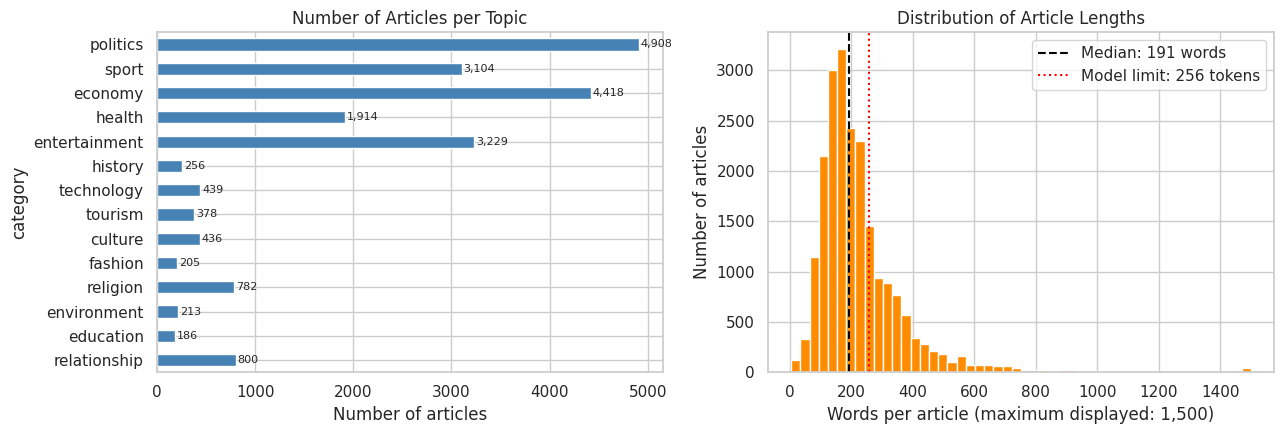

Duplicate articles: 10,185 / 21,268 (47.9%)
Test articles also found in training: 2,226 / 4,254 (52.3%)
Interpretation: Exact overlap can make test performance look better than it really is.


In [8]:

# ── Explore article categories and lengths ─────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Number of articles in each topic
topic_counts = df["category"].value_counts()
topic_counts = topic_counts.reindex(
    [topic for topic in ALL_TOPICS if topic in topic_counts.index]
)

topic_counts.plot.barh(ax=axes[0], color="steelblue")
axes[0].invert_yaxis()
axes[0].set_title("Number of Articles per Topic")
axes[0].set_xlabel("Number of articles")

# Add article counts beside the bars
for position, count in enumerate(topic_counts):
    axes[0].text(count + 20, position, f"{count:,}", va="center", fontsize=8)


# 2. Distribution of article lengths
word_counts = df["text"].str.split().str.len()
median_words = int(word_counts.median())

# Clip long articles at 1,500 words to make the histogram easier to read
axes[1].hist(word_counts.clip(upper=1500), bins=50, color="darkorange")

# Show the median article length and the model's maximum input length
axes[1].axvline(
    median_words, color="black", linestyle="--",
    label=f"Median: {median_words} words"
)
axes[1].axvline(
    MAX_LEN, color="red", linestyle=":",
    label=f"Model limit: {MAX_LEN} tokens"
)

axes[1].set_title("Distribution of Article Lengths")
axes[1].set_xlabel("Words per article (maximum displayed: 1,500)")
axes[1].set_ylabel("Number of articles")
axes[1].legend()

plt.tight_layout()
plt.show()


# ── Check for duplicate articles and train-test overlap ────────────────

# Count exact duplicates across the combined dataset
n_duplicates = df.duplicated(subset=["title", "content"]).sum()

# Store the title and content of every training article
train_articles = set(
    zip(
        df.loc[df["source_split"] == "train", "title"],
        df.loc[df["source_split"] == "train", "content"]
    )
)

# Check whether any test articles also exist in the training file
test_articles = df[df["source_split"] == "test"]

n_overlap = sum(
    (title, content) in train_articles
    for title, content in zip(test_articles["title"], test_articles["content"])
)

# Display the results
print(
    f"Duplicate articles: {n_duplicates:,} / {len(df):,} "
    f"({n_duplicates / len(df):.1%})"
)

print(
    f"Test articles also found in training: {n_overlap:,} / "
    f"{len(test_articles):,} ({n_overlap / len(test_articles):.1%})"
)

print(
    "Interpretation: Exact overlap can make test performance look "
    "better than it really is."
)


## 4. Clean the data

We clean the articles with **one function, `basic_cleaning()`**, in the same way for every experiment (and later in the app).

### What we clean (and why)
| Step | Why |
|---|---|
| Decode HTML codes (`&amp;` → `&`) | web-page noise |
| Normalise unicode (NFKC) | turns special spaces (`\xa0`) and look-alike characters into one form |
| Remove invisible characters | they split words in two |
| Remove links and e-mail addresses | random strings, no topic information |
| Lower-case | `Inkino` and `inkino` become one word |
| Squeeze spaces | tidy text |

### What we deliberately do **not** do
* **No stop-word removal, no stemming:** reliable tools for Kinyarwanda and Kirundi are not available, and a wrong rule would damage the text.
* **Numbers and punctuation stay:** scores, dates and amounts are useful hints (sport, economy).

After that we remove **empty articles**, **articles with conflicting labels** (the same text labelled with two different topics) and **duplicates** (same text; the first copy is kept). Because the train file comes first, a test article that is also in train is removed from test.

In [9]:
# ── ONE function does all the cleaning: one clear step per line ───────────
def basic_cleaning(text):
    text = html.unescape(str(text))                                    # &amp; -> &
    text = unicodedata.normalize("NFKC", text)                         # for making sure that look-alike characters (like \xa0) are all in one form
    text = re.sub(r"[\u200b\u2060\ufeff\u00ad]", "", text)             # invisible characters
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)                 # links
    text = re.sub(r"\S+@\S+\.\S+", " ", text)                          # e-mail addresses
    text = text.lower()                                                # lower-case
    return re.sub(r"\s+", " ", text).strip()                           # extra spaces

# Quick test on a made-up example
example = "Primus Ligue\xa0: Imirwi &amp; amakipe  https://example.com/x"
print("before:", repr(example))
print("after :", repr(basic_cleaning(example)))

before: 'Primus Ligue\xa0: Imirwi &amp; amakipe  https://example.com/x'
after : 'primus ligue : imirwi & amakipe'
before: 'Primus Ligue\xa0: Imirwi &amp; amakipe  https://example.com/x'
after : 'primus ligue : imirwi & amakipe'


In [10]:

# ── Clean article text and remove problematic records ──────────────────

# Save the original counts so we can measure the effect of cleaning
original_count = len(df)
topic_order = [topic for topic in ALL_TOPICS if topic in df["category"].values]
counts_before = df["category"].value_counts()

# 1. Clean the article text
df["text"] = df["text"].map(basic_cleaning)

# 2. Remove articles that become empty after cleaning
df = df[df["text"] != ""].copy()
empty_removed = original_count - len(df)

# 3. Find identical text assigned to different categories
# These labels conflict, so remove all copies of the affected text
topics_per_text = df.groupby("text")["category"].nunique()
conflicting_texts = topics_per_text[topics_per_text > 1].index

before_conflict_removal = len(df)
df = df[~df["text"].isin(conflicting_texts)].copy()
conflicts_removed = before_conflict_removal - len(df)

# 4. Remove exact duplicate text, keeping the first occurrence
before_duplicate_removal = len(df)
df = df.drop_duplicates(subset="text", keep="first").reset_index(drop=True)
duplicates_removed = before_duplicate_removal - len(df)

# ── Summarize the cleaning results ────────────────────────────────────

print(f"Articles before cleaning:          {original_count:,}")
print(f"Empty articles removed:            {empty_removed:,}")
print(f"Articles removed due to conflicts: {conflicts_removed:,}")
print(f"Duplicate articles removed:        {duplicates_removed:,}")
print(f"Articles remaining:                {len(df):,}")
print(f"Percentage retained:               {len(df) / original_count:.1%}")

# Compare category counts before and after cleaning
counts_after = df["category"].value_counts()

cleaning_summary = pd.DataFrame({
    "Before": counts_before,
    "After": counts_after
}).reindex(topic_order).fillna(0).astype(int)

display(cleaning_summary)


Articles before cleaning:          21,268
Empty articles removed:            0
Articles removed due to conflicts: 1,453
Duplicate articles removed:        8,891
Articles remaining:                10,924
Percentage retained:               51.4%


,Before,After
category,,
politics,4908,2082
sport,3104,1718
economy,4418,1283
health,1914,1355
entertainment,3229,1769
history,256,229
technology,439,253
tourism,378,109
culture,436,215


In [11]:

# ── Remove topics with too few articles ───────────────────────────────

# Count how many articles belong to each topic
topic_counts = df["category"].value_counts()

# Identify topics that do not meet the minimum requirement
too_small = topic_counts[topic_counts < MIN_ARTICLES_PER_CLASS]

if not too_small.empty:
    print(f"Removing {len(too_small)} topic(s) with fewer than "
          f"{MIN_ARTICLES_PER_CLASS} articles:")
    print(too_small.to_string())

    # Remove all articles belonging to these topics
    df = df[~df["category"].isin(too_small.index)].reset_index(drop=True)
else:
    print("All topics meet the minimum article requirement.")


# ── Create labels for model training ──────────────────────────────────

# Keep a consistent topic order across all models
LABELS = [topic for topic in ALL_TOPICS if topic in df["category"].values]

# Create a numeric ID for each topic (0, 1, 2, ...)
label_to_id = {label: i for i, label in enumerate(LABELS)}

# Convert category names into numeric labels for machine learning
df["y"] = df["category"].map(label_to_id)

N_CLASSES = len(LABELS)

print(f"\nLanguage: {info['language']}")
print(f"Number of topics: {N_CLASSES}")
print(f"Topics: {LABELS}")
print(f"Articles remaining: {len(df):,}")


All topics meet the minimum article requirement.

Language: Kinyarwanda
Number of topics: 14
Topics: ['politics', 'sport', 'economy', 'health', 'entertainment', 'history', 'technology', 'tourism', 'culture', 'fashion', 'religion', 'environment', 'education', 'relationship']
Articles remaining: 10,924


## 5. Split the data

* **`SPLIT_MODE = "general"` (default):** all cleaned, unique articles are split **once** into **70% train / 15% validation / 15% test**, stratified by topic (every split has the same topic proportions), with a fixed seed. **Every experiment uses exactly these same three sets**, so the comparison is fair.
* **`SPLIT_MODE = "official"`:** keep the official train and test files (after removing duplicates). The validation set is 15% of the train file.

In [12]:

# ── Split the dataset into train, validation, and test sets ────────────

if SPLIT_MODE == "general":
    # Create a new 70/15/15-style split using the full dataset.
    # Stratification keeps topic proportions similar across the splits.
    train, rest = train_test_split(
        df,
        test_size=VAL_SHARE + TEST_SHARE,
        stratify=df["category"],
        random_state=SEED
    )

    # Divide the remaining data into validation and test sets
    validation, test = train_test_split(
        rest,
        test_size=TEST_SHARE / (VAL_SHARE + TEST_SHARE),
        stratify=rest["category"],
        random_state=SEED
    )

else:
    # Preserve the dataset's official test set
    official_train = df[df["source_split"] == "train"]
    test = df[df["source_split"] == "test"]

    # Split the official training data to create a validation set
    train, validation = train_test_split(
        official_train,
        test_size=VAL_SHARE,
        stratify=official_train["category"],
        random_state=SEED
    )


# Reset row indices after splitting
train, validation, test = [
    split.reset_index(drop=True)
    for split in (train, validation, test)
]


# ── Prepare text and labels for machine learning ──────────────────────

# Extract article text as Python lists
train_text = train["text"].tolist()
val_text = validation["text"].tolist()
test_text = test["text"].tolist()

# Extract numeric labels as NumPy arrays
y_train = train["y"].to_numpy()
y_val = validation["y"].to_numpy()
y_test = test["y"].to_numpy()


# ── Check the split sizes and topic distribution ──────────────────────

print(f"Split mode: {SPLIT_MODE}")
print(f"Training articles:   {len(train):,}")
print(f"Validation articles: {len(validation):,}")
print(f"Test articles:       {len(test):,}")

# Compare the number of articles per topic in each split
split_summary = pd.DataFrame({
    "train": train["category"].value_counts(),
    "validation": validation["category"].value_counts(),
    "test": test["category"].value_counts()
}).reindex(LABELS).fillna(0).astype(int)

# Add a total column for each topic
split_summary["total"] = split_summary.sum(axis=1)

display(split_summary)


Split mode: general
Training articles:   7,646
Validation articles: 1,639
Test articles:       1,639


,train,validation,test,total
category,,,,
politics,1457,312,313,2082
sport,1203,258,257,1718
economy,898,193,192,1283
health,948,203,204,1355
entertainment,1238,266,265,1769
history,160,35,34,229
technology,177,38,38,253
tourism,76,16,17,109
culture,151,32,32,215


## 6. reusable functions (used by every experiment)

Small helpers so that **every model is scored in exactly the same way**:

* `get_scores(y_true, probs)` → macro-F1, weighted-F1, accuracy, log loss
* `show_report(...)` → per-topic precision / recall / F1 and a confusion matrix
* `register_model(...)` → keeps every trained model in one place (used by the comparison, the error analysis and the app)

All models give **probabilities** (one per topic) and the predicted topic is the one with the highest probability.

In [13]:

# ── 1. Define the class IDs ────────────────────────────────────────────

# Keep class order consistent across all models and evaluation reports
ALL_CLASSES = list(range(N_CLASSES))


# ── 2. Calculate model evaluation scores ───────────────────────────────

def get_scores(y_true, probs):
    """Calculate F1 scores, accuracy, and log loss."""

    # Prevent invalid probabilities and ensure each row sums to 1
    probs = np.clip(probs, 1e-12, 1.0)
    probs = probs / probs.sum(axis=1, keepdims=True)

    # Select the class with the highest predicted probability
    predictions = probs.argmax(axis=1)

    return {
        "macro_f1": f1_score(
            y_true, predictions,
            average="macro", labels=ALL_CLASSES, zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, predictions,
            average="weighted", labels=ALL_CLASSES, zero_division=0
        ),
        "accuracy": accuracy_score(y_true, predictions),
        "log_loss": log_loss(y_true, probs, labels=ALL_CLASSES)
    }


# ── 3. Visualize classification errors ─────────────────────────────────

def plot_confusion(title, y_true, predictions):
    """Plot a confusion matrix showing the percentage for each true class."""

    # Count correct predictions and misclassifications
    counts = confusion_matrix(y_true, predictions, labels=ALL_CLASSES)

    # Normalize each row so it represents percentages within a true class
    row_totals = counts.sum(axis=1, keepdims=True)
    percentages = counts / np.maximum(row_totals, 1)

    # Adjust figure size based on the number of topics
    size = max(5, 0.55 * N_CLASSES + 2)
    plt.figure(figsize=(size, size * 0.85))

    sns.heatmap(
        percentages,
        annot=True,
        fmt=".0%",
        cmap="Blues",
        xticklabels=LABELS,
        yticklabels=LABELS,
        cbar=False,
        annot_kws={"size": 7},
        vmin=0,
        vmax=1
    )

    plt.title(title)
    plt.xlabel("Predicted topic")
    plt.ylabel("True topic")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()


def show_report(title, y_true, probs):
    """Print per-topic metrics and display the confusion matrix."""

    predictions = probs.argmax(axis=1)

    # Show precision, recall, F1, and support for each topic
    print(classification_report(
        y_true,
        predictions,
        labels=ALL_CLASSES,
        target_names=LABELS,
        zero_division=0,
        digits=3
    ))

    plot_confusion(title, y_true, predictions)


# ── 4. Record experiment results ───────────────────────────────────────

# Store one record for each experiment
experiment_log = []


def log_experiment(name, notes, settings, val_scores, cv_scores):
    """Save experiment details and validation results for comparison."""

    experiment_log.append({
        "experiment": name,
        "notes": notes,
        "settings": str(settings),
        "val_macro_f1": val_scores["macro_f1"],
        "val_accuracy": val_scores["accuracy"],
        "val_log_loss": val_scores["log_loss"],
        "cv_macro_f1": (
            None if cv_scores is None
            else cv_scores["macro_f1_mean"]
        )
    })


# ── 5. Store trained models and their results ──────────────────────────

# MODELS stores trained models; RESULT_INFO stores their experiment details
MODELS = {}
RESULT_INFO = {}


def register_model(key, experiment, model, val_scores, cv_scores, settings=None):
    """Save a trained model and its evaluation information."""

    MODELS[key] = model

    RESULT_INFO[key] = {
        "experiment": experiment,
        "val_scores": val_scores,
        "cv_scores": cv_scores,
        "settings": dict(settings or {})
    }


---
## Experiment 0: Baseline (majority class)

**Idea:** the simplest "model": it ignores the text and always predicts the topic shares of the training data (so it always answers with the most common topic). Every real model must beat this. If a model scores about the same, it has learned nothing.

In [14]:

# ── Train a simple baseline model ──────────────────────────────────────

# The baseline predicts classes using their frequencies in the training data
settings = {"strategy": "prior"}


def run_experiment(name, notes):
    """Train the baseline and evaluate it using 5-fold CV and validation data."""

    # Create a simple model to compare against more advanced models
    model = DummyClassifier(strategy=settings["strategy"])

    # Evaluate the baseline using 5-fold cross-validation
    cv = cross_validate(
        model,
        train_text,
        y_train,
        cv=5,
        scoring="f1_macro"
    )

    # Summarize cross-validation scores
    cv_scores = {
        "macro_f1_mean": cv["test_score"].mean(),
        "macro_f1_std": cv["test_score"].std()
    }

    # Train on all training data and predict validation probabilities
    model.fit(train_text, y_train)
    val_probs = model.predict_proba(val_text)

    # Calculate validation metrics
    val_scores = get_scores(y_val, val_probs)

    # Save results for comparison with future experiments
    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


# ── Run and save the baseline experiment ───────────────────────────────

base_model, base_val_probs, base_val_scores, base_cv_scores = run_experiment(
    "majority_baseline",
    "Simple baseline using the training class frequencies."
)

register_model(
    "majority_baseline",
    "majority_baseline",
    base_model,
    base_val_scores,
    base_cv_scores,
    settings
)

# Display validation results
print("Validation scores:")
print({metric: round(score, 4) for metric, score in base_val_scores.items()})

print(
    f"5-fold CV macro-F1: "
    f"{base_cv_scores['macro_f1_mean']:.4f} "
    f"± {base_cv_scores['macro_f1_std']:.4f}"
)


Validation scores:
{'macro_f1': 0.0228, 'weighted_f1': 0.0609, 'accuracy': 0.1904, 'log_loss': 2.2404}
5-fold CV macro-F1: 0.0229 ± 0.0000


---
## Experiment 1: TF-IDF + Logistic Regression

**Idea:** turn each article into numbers with TF-IDF (single words *and* 2-word phrases) and learn which words point to which topic. A strong, fast text baseline.
**Class weights = "balanced":** mistakes on the rarer topics count more, which helps small topics like *education* or *fashion*.

In [15]:

# ── Logistic Regression with TF-IDF features ───────────────────────────

# Model settings
settings = {
    "ngram_range": (1, 2),       # Use single words and two-word phrases
    "class_weight": "balanced",  # Give more weight to underrepresented topics
    "C": 1.0,                   # Controls regularization strength
    "max_features": 300_000      # Maximum number of TF-IDF features
}


def run_experiment(name, notes):
    """Train Logistic Regression and evaluate it using CV and validation data."""

    # 1. Convert text into TF-IDF features, then train the classifier
    model = make_pipeline(
        TfidfVectorizer(
            ngram_range=settings["ngram_range"],
            sublinear_tf=True,
            min_df=2,
            max_features=settings["max_features"]
        ),
        LogisticRegression(
            C=settings["C"],
            class_weight=settings["class_weight"],
            max_iter=300
        )
    )

    # 2. Evaluate performance using 5-fold cross-validation
    cv = cross_validate(
        model,
        train_text,
        y_train,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    cv_scores = {
        "macro_f1_mean": cv["test_score"].mean(),
        "macro_f1_std": cv["test_score"].std()
    }

    # 3. Train on all training data and evaluate on the validation set
    model.fit(train_text, y_train)
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    # 4. Record the results for later comparison
    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


# ── Run and register the experiment ────────────────────────────────────

lr_model, lr_val_probs, lr_val_scores, lr_cv_scores = run_experiment(
    "word_bigrams_balanced",
    "Word unigrams and bigrams with balanced class weights."
)

register_model(
    "logistic_regression",
    "word_bigrams_balanced",
    lr_model,
    lr_val_scores,
    lr_cv_scores,
    settings
)

# Display validation and cross-validation results
print("Validation scores:")
print({metric: round(score, 4) for metric, score in lr_val_scores.items()})

print(
    f"5-fold CV macro-F1: {lr_cv_scores['macro_f1_mean']:.4f} "
    f"± {lr_cv_scores['macro_f1_std']:.4f}"
)


Validation scores:
{'macro_f1': 0.7074, 'weighted_f1': 0.788, 'accuracy': 0.7877, 'log_loss': 1.1395}
5-fold CV macro-F1: 0.7252 ± 0.0115


               precision    recall  f1-score   support

     politics      0.771     0.702     0.735       312
        sport      0.964     0.926     0.945       258
      economy      0.694     0.777     0.733       193
       health      0.707     0.749     0.727       203
entertainment      0.890     0.820     0.853       266
      history      0.514     0.514     0.514        35
   technology      0.707     0.763     0.734        38
      tourism      0.600     0.562     0.581        16
      culture      0.567     0.531     0.548        32
      fashion      0.842     0.842     0.842        19
     religion      0.825     0.895     0.858       105
  environment      0.583     0.350     0.438        20
    education      0.447     0.607     0.515        28
 relationship      0.835     0.930     0.880       114

     accuracy                          0.788      1639
    macro avg      0.710     0.712     0.707      1639
 weighted avg      0.792     0.788     0.788      1639

       

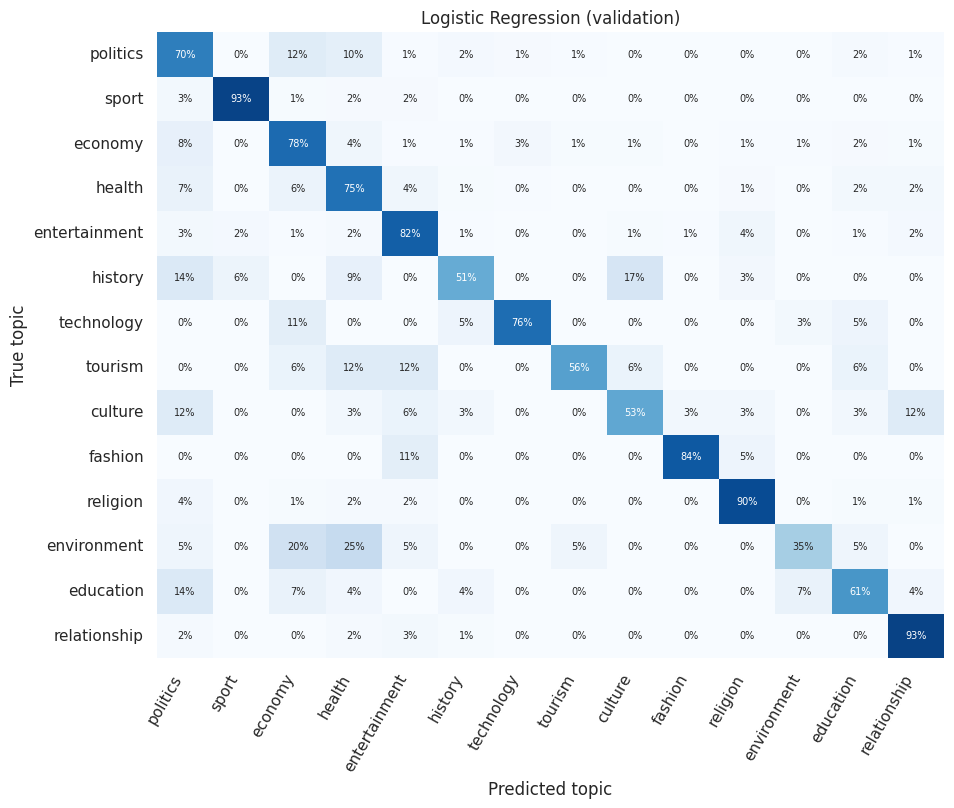

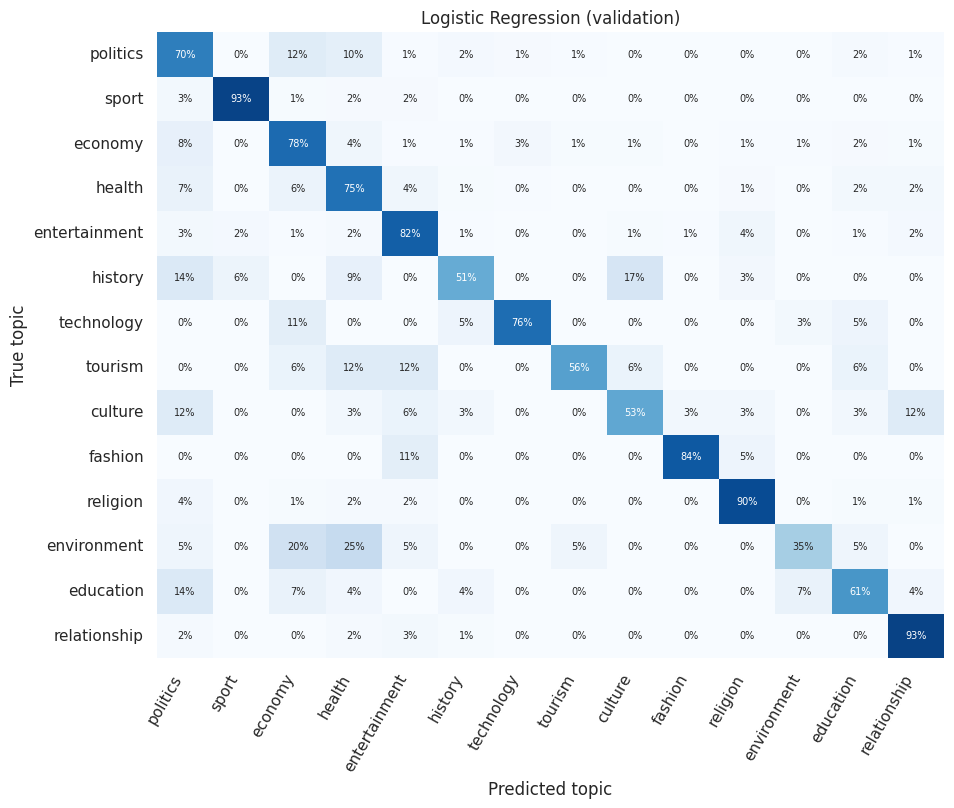

In [16]:
show_report("Logistic Regression (validation)", y_val, lr_val_probs)

---
## Experiment 2: TF-IDF + Complement Naive Bayes

**Idea:** count how often each word appears in each topic and use Bayes' rule. It is the fastest model here.
**Complement NB** is a version designed for **imbalanced classes**. `alpha` is the smoothing strength (how much probability unseen words get).

In [17]:

# ── Complement Naive Bayes with TF-IDF features ────────────────────────

# Model settings
settings = {
    "ngram_range": (1, 2),       # Use single words and two-word phrases
    "alpha": 0.1,                # Controls smoothing
    "max_features": 300_000      # Maximum number of TF-IDF features
}


def run_experiment(name, notes):
    """Train Complement Naive Bayes and evaluate its performance."""

    # 1. Convert article text into TF-IDF features and build the classifier
    model = make_pipeline(
        TfidfVectorizer(
            ngram_range=settings["ngram_range"],
            min_df=2,
            max_features=settings["max_features"]
        ),
        ComplementNB(alpha=settings["alpha"])
    )

    # 2. Evaluate using 5-fold cross-validation on the training data
    cv = cross_validate(
        model,
        train_text,
        y_train,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    cv_scores = {
        "macro_f1_mean": cv["test_score"].mean(),
        "macro_f1_std": cv["test_score"].std()
    }

    # 3. Train on all training data and evaluate on validation data
    model.fit(train_text, y_train)
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    # 4. Save the experiment results
    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


# ── Run and register the experiment ────────────────────────────────────

nb_model, nb_val_probs, nb_val_scores, nb_cv_scores = run_experiment(
    "complement_nb_bigrams",
    "Complement Naive Bayes with TF-IDF unigrams and bigrams."
)

register_model(
    "naive_bayes",
    "complement_nb_bigrams",
    nb_model,
    nb_val_scores,
    nb_cv_scores,
    settings
)

# Display validation and cross-validation results
print("Validation scores:")
print({metric: round(score, 4) for metric, score in nb_val_scores.items()})

print(
    f"5-fold CV macro-F1: {nb_cv_scores['macro_f1_mean']:.4f} "
    f"± {nb_cv_scores['macro_f1_std']:.4f}"
)


Validation scores:
{'macro_f1': 0.624, 'weighted_f1': 0.7742, 'accuracy': 0.7858, 'log_loss': 0.9895}
5-fold CV macro-F1: 0.6603 ± 0.0152


               precision    recall  f1-score   support

     politics      0.700     0.808     0.750       312
        sport      0.941     0.981     0.960       258
      economy      0.637     0.782     0.702       193
       health      0.781     0.704     0.741       203
entertainment      0.848     0.898     0.872       266
      history      0.786     0.314     0.449        35
   technology      0.765     0.342     0.473        38
      tourism      0.700     0.438     0.538        16
      culture      0.636     0.438     0.519        32
      fashion      0.727     0.421     0.533        19
     religion      0.853     0.829     0.841       105
  environment      0.000     0.000     0.000        20
    education      0.833     0.357     0.500        28
 relationship      0.840     0.877     0.858       114

     accuracy                          0.786      1639
    macro avg      0.718     0.585     0.624      1639
 weighted avg      0.780     0.786     0.774      1639



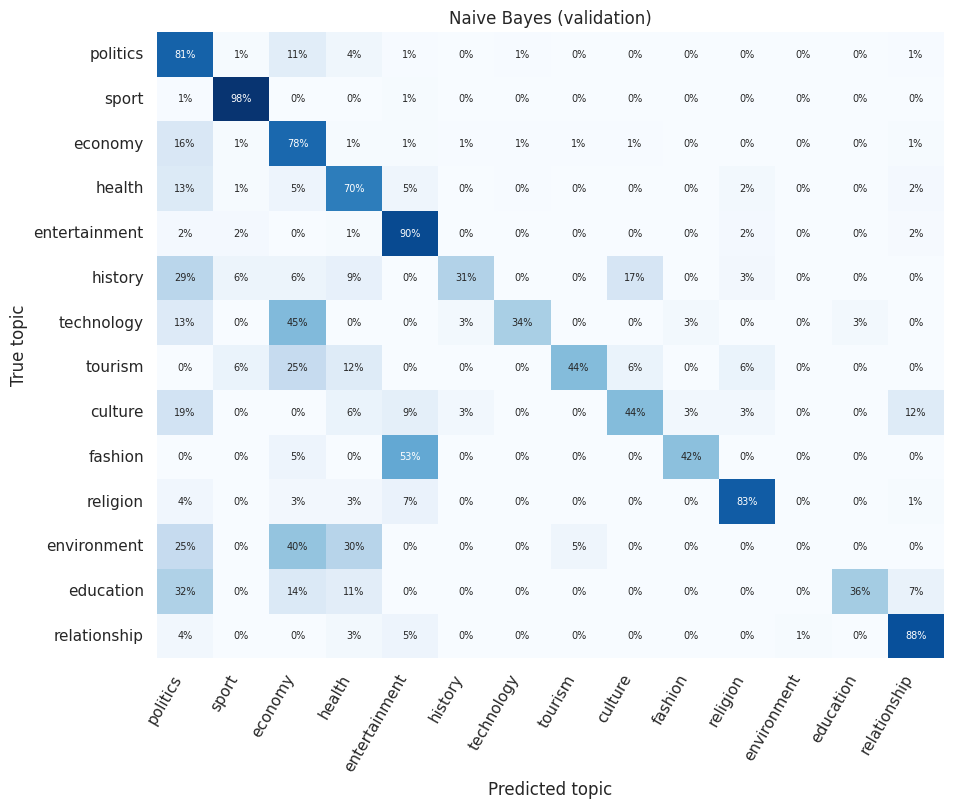

In [18]:
show_report("Naive Bayes (validation)", y_val, nb_val_probs)

---
## Tools for the neural experiments (CNN, BiLSTM, Word2Vec)

A neural network cannot read text, so we convert it step by step:

```
article  ->  words  ->  numbers (vocabulary)  ->  same length (pad/cut)  ->  network  ->  one probability per topic
```

This section prepares everything **once**:

1. `tokenize`: split an article into words.
2. `vocab`: a dictionary word → number, built from **training articles only**.
3. `NeuralTextClassifier`: a small wrapper so a neural model has the **same `.predict_proba(texts)`** as the scikit-learn models.
4. `train_network`: the training loop. After each epoch it checks validation macro-F1 and **keeps the best epoch** (early stopping).

In [19]:

# ── 1. Special word IDs ────────────────────────────────────────────────
PAD = 0  # Used to fill short articles
UNK = 1  # Used for words not found in the vocabulary


# ── 2. Tokenize text ──────────────────────────────────────────────────
def tokenize(text):
    """Convert text to lowercase words."""
    return re.findall(r"[\w']+", str(text).lower())


# ── 3. Build vocabulary using training data only ───────────────────────
# Keep words that appear at least twice.
word_counts = Counter(
    word
    for text in train_text
    for word in tokenize(text)
)

vocab = {"<pad>": PAD, "<unk>": UNK}

for word, count in sorted(word_counts.items()):
    if count >= 2:
        vocab[word] = len(vocab)

print("Vocabulary size:", len(vocab))


# ── 4. Convert articles into numerical sequences ──────────────────────
def encode(texts, max_len):
    """Convert articles into equal-length sequences of word IDs."""
    rows = []

    for text in texts:
        # Convert words into IDs; use UNK for unseen words.
        word_ids = [
            vocab.get(word, UNK)
            for word in tokenize(text)[:max_len]
        ]

        # Pad short articles so every sequence has the same length.
        word_ids += [PAD] * (max_len - len(word_ids))
        rows.append(word_ids)

    return torch.tensor(rows, dtype=torch.long)


# ── 5. Make the neural network compatible with model evaluation ───────
class NeuralTextClassifier:
    """Wrapper that provides a predict_proba() method."""

    def __init__(self, network, max_len):
        self.network = network
        self.max_len = max_len

    @torch.no_grad()
    def predict_proba(self, texts):
        """Return a probability for each class for every article."""
        self.network.eval()

        # Convert articles into the numerical format the network expects.
        x = encode(texts, self.max_len)
        batches = []

        # Process small batches to reduce memory usage.
        for start in range(0, len(x), 256):
            batch = x[start:start + 256].to(device)

            # Get model outputs and convert them into probabilities.
            logits = self.network(batch)
            probabilities = F.softmax(logits, dim=1)

            batches.append(probabilities.cpu().numpy())

        # Combine predictions from all batches.
        return np.vstack(batches)


Vocabulary size: 71388


In [20]:

# ── Train the neural network ──────────────────────────────────────────
def train_network(network, settings):
    """Train the network and return the version with the best validation macro-F1."""

    set_seed(SEED)
    network = network.to(device)

    # Convert training articles into word IDs.
    x_train = encode(train_text, settings["max_len"])
    y_tensor = torch.tensor(y_train, dtype=torch.long)

    # Give rare classes more weight if class weighting is enabled.
    weights = None
    if settings["class_weights"]:
        class_weights = compute_class_weight(
            class_weight="balanced",
            classes=np.arange(N_CLASSES),
            y=y_train
        )
        weights = torch.tensor(
            class_weights, dtype=torch.float32, device=device
        )

    loss_function = nn.CrossEntropyLoss(weight=weights)
    optimizer = torch.optim.Adam(
        network.parameters(), lr=settings["lr"]
    )

    # Load training data in shuffled batches.
    loader = DataLoader(
        TensorDataset(x_train, y_tensor),
        batch_size=settings["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(SEED)
    )

    # Track the best model and training progress.
    best_f1 = -1.0
    best_weights = None
    epochs_without_gain = 0
    history = []

    for epoch in range(1, settings["epochs"] + 1):
        # ── Training phase ────────────────────────────────────────────
        network.train()
        total_loss = 0.0

        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            loss = loss_function(network(xb), yb)
            loss.backward()

            # Limit gradients to help prevent unstable updates.
            nn.utils.clip_grad_norm_(network.parameters(), max_norm=5.0)
            optimizer.step()

            total_loss += loss.item() * len(xb)

        average_loss = total_loss / len(y_train)

        # ── Validation phase ──────────────────────────────────────────
        classifier = NeuralTextClassifier(network, settings["max_len"])
        val_probs = classifier.predict_proba(val_text)
        val_predictions = val_probs.argmax(axis=1)

        val_f1 = f1_score(
            y_val,
            val_predictions,
            average="macro",
            labels=ALL_CLASSES,
            zero_division=0
        )

        history.append((epoch, average_loss, val_f1))

        print(
            f"Epoch {epoch:2d} | "
            f"Training loss: {average_loss:.4f} | "
            f"Validation macro-F1: {val_f1:.4f}"
        )

        # ── Save the best model and apply early stopping ───────────────
        if val_f1 > best_f1 + 1e-4:
            best_f1 = val_f1
            epochs_without_gain = 0

            # Save a copy of the model's best parameters.
            best_weights = {
                name: value.detach().clone()
                for name, value in network.state_dict().items()
            }
        else:
            epochs_without_gain += 1

            if epochs_without_gain >= settings["patience"]:
                print("Early stopping: validation macro-F1 did not improve.")
                break

    # Restore the best-performing version of the network.
    if best_weights is not None:
        network.load_state_dict(best_weights)

    # ── Plot training progress ─────────────────────────────────────────
    history_df = pd.DataFrame(
        history,
        columns=["epoch", "train_loss", "val_macro_f1"]
    )

    fig, axes = plt.subplots(1, 2, figsize=(10, 3))

    axes[0].plot(history_df["epoch"], history_df["train_loss"])
    axes[0].set_title("Training Loss")
    axes[0].set_xlabel("Epoch")

    axes[1].plot(history_df["epoch"], history_df["val_macro_f1"])
    axes[1].set_title("Validation Macro-F1")
    axes[1].set_xlabel("Epoch")

    plt.tight_layout()
    plt.show()

    return network


---
## Experiment 3: CNN

**Idea:** a 1D convolutional network slides small windows (3, 4 and 5 words wide) over the article. Each window detector learns to spot a **key phrase** (for example the name of a league or a minister). The strongest match of each detector is kept and used to classify. It is fast and works well for topic classification.
**Class weights** are switched on so the rarer topics are not ignored.

Epoch  1 | Training loss: 2.9127 | Validation macro-F1: 0.1420
Epoch  2 | Training loss: 2.4080 | Validation macro-F1: 0.3241
Epoch  3 | Training loss: 1.9922 | Validation macro-F1: 0.3933
Epoch  4 | Training loss: 1.7610 | Validation macro-F1: 0.4836
Epoch  5 | Training loss: 1.5643 | Validation macro-F1: 0.5181
Epoch  6 | Training loss: 1.4146 | Validation macro-F1: 0.5339
Epoch  7 | Training loss: 1.2938 | Validation macro-F1: 0.5418
Epoch  8 | Training loss: 1.1893 | Validation macro-F1: 0.5361
Epoch  9 | Training loss: 1.0744 | Validation macro-F1: 0.5726
Epoch 10 | Training loss: 1.0331 | Validation macro-F1: 0.5634
Epoch 11 | Training loss: 1.0101 | Validation macro-F1: 0.5727
Epoch 12 | Training loss: 0.9419 | Validation macro-F1: 0.5956
Epoch 13 | Training loss: 0.8803 | Validation macro-F1: 0.5992
Epoch 14 | Training loss: 0.8159 | Validation macro-F1: 0.6086
Epoch 15 | Training loss: 0.7738 | Validation macro-F1: 0.5912


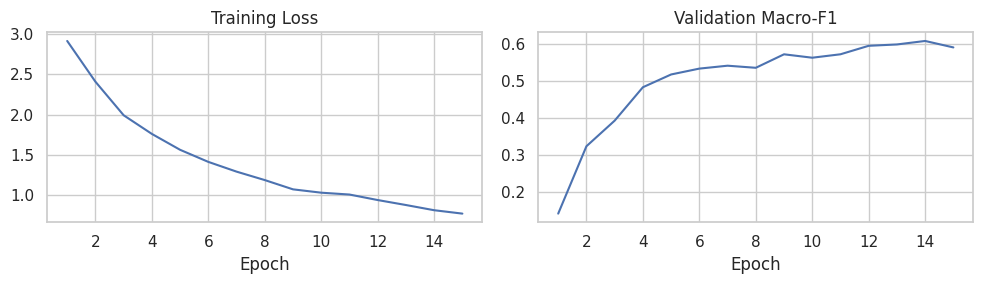

Validation scores: {'macro_f1': 0.6086, 'weighted_f1': 0.6775, 'accuracy': 0.676, 'log_loss': 1.0026}


In [21]:

# ── 1. Define the TextCNN model ───────────────────────────────────────
class TextCNN(nn.Module):
    """Classify text using word embeddings and convolutional filters."""

    def __init__(
        self, vocab_size, emb_dim, kernel_sizes,
        n_filters, dropout, n_classes
    ):
        super().__init__()

        # Convert each word ID into a dense vector.
        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=PAD
        )

        # Detect patterns of different lengths in the text.
        self.convs = nn.ModuleList([
            nn.Conv1d(emb_dim, n_filters, kernel_size, padding=kernel_size // 2)
            for kernel_size in kernel_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        # Predict the article's topic from the extracted features.
        self.classifier = nn.Linear(
            n_filters * len(kernel_sizes), n_classes
        )

    def forward(self, x):
        # Word IDs → embeddings: (batch, length, embedding size).
        x = self.embedding(x)

        # Conv1d expects: (batch, embedding size, length).
        x = x.transpose(1, 2)

        # Apply each filter, ReLU, and max-pooling.
        features = [
            F.relu(conv(x)).max(dim=2).values
            for conv in self.convs
        ]

        # Combine features and predict class scores (logits).
        x = torch.cat(features, dim=1)
        x = self.dropout(x)

        return self.classifier(x)


# ── 2. Configure the CNN experiment ───────────────────────────────────
settings = {
    "max_len": MAX_LEN,
    "emb_dim": 100,
    "kernel_sizes": (3, 4, 5),
    "n_filters": 100,
    "dropout": 0.5,
    "class_weights": True,
    "lr": 1e-3,
    "batch_size": 64,
    "epochs": 15,
    "patience": 4
}


# ── 3. Train and evaluate the CNN ─────────────────────────────────────
def run_experiment(name, notes):
    """Train the CNN and evaluate its validation performance."""

    network = TextCNN(
        vocab_size=len(vocab),
        emb_dim=settings["emb_dim"],
        kernel_sizes=settings["kernel_sizes"],
        n_filters=settings["n_filters"],
        dropout=settings["dropout"],
        n_classes=N_CLASSES
    )

    network = train_network(network, settings)

    # Get the predicted probability for each topic.
    model = NeuralTextClassifier(network, settings["max_len"])
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    # Skip cross-validation because training neural networks repeatedly is costly.
    cv_scores = None

    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


# ── 4. Run, save, and display results ─────────────────────────────────
cnn_model, cnn_val_probs, cnn_val_scores, cnn_cv_scores = run_experiment(
    "cnn_class_weights",
    "TextCNN with kernel sizes 3, 4, and 5, using class weights."
)

register_model(
    "cnn",
    "cnn_class_weights",
    cnn_model,
    cnn_val_scores,
    cnn_cv_scores,
    settings
)

print("Validation scores:", {
    metric: round(score, 4)
    for metric, score in cnn_val_scores.items()
})


               precision    recall  f1-score   support

     politics      0.685     0.510     0.585       312
        sport      0.926     0.922     0.924       258
      economy      0.633     0.420     0.505       193
       health      0.436     0.808     0.566       203
entertainment      0.883     0.711     0.787       266
      history      0.385     0.429     0.405        35
   technology      0.386     0.711     0.500        38
      tourism      0.636     0.438     0.519        16
      culture      0.542     0.406     0.464        32
      fashion      0.682     0.789     0.732        19
     religion      0.724     0.800     0.760       105
  environment      0.667     0.300     0.414        20
    education      0.619     0.464     0.531        28
 relationship      0.808     0.851     0.829       114

     accuracy                          0.676      1639
    macro avg      0.644     0.611     0.609      1639
 weighted avg      0.711     0.676     0.678      1639

       

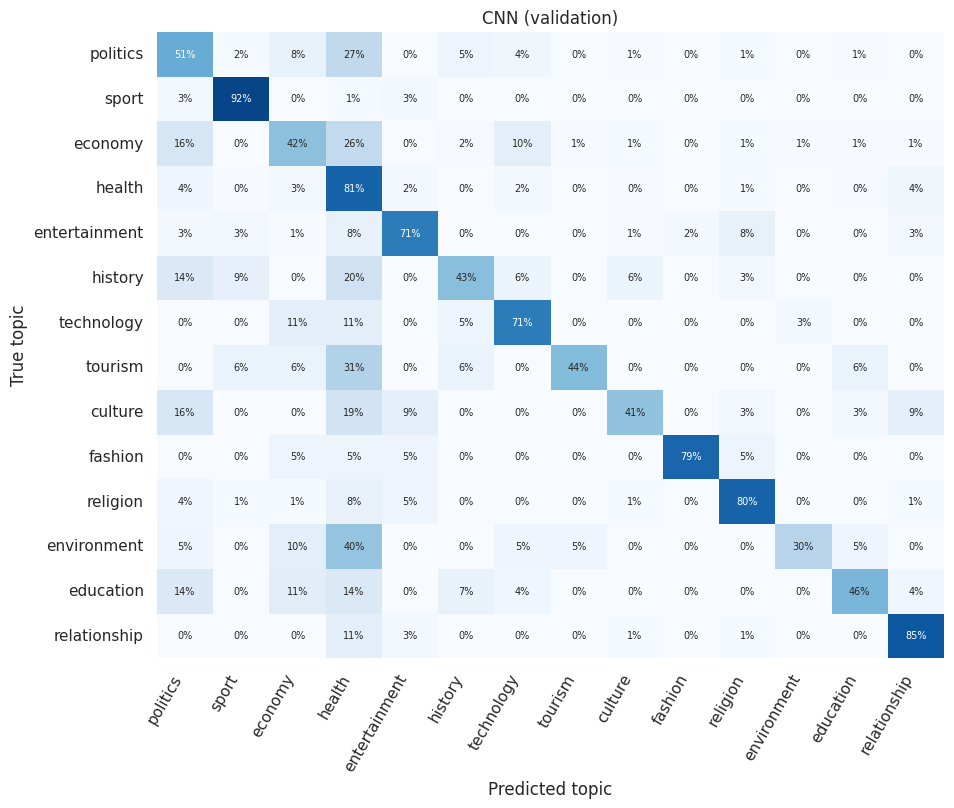

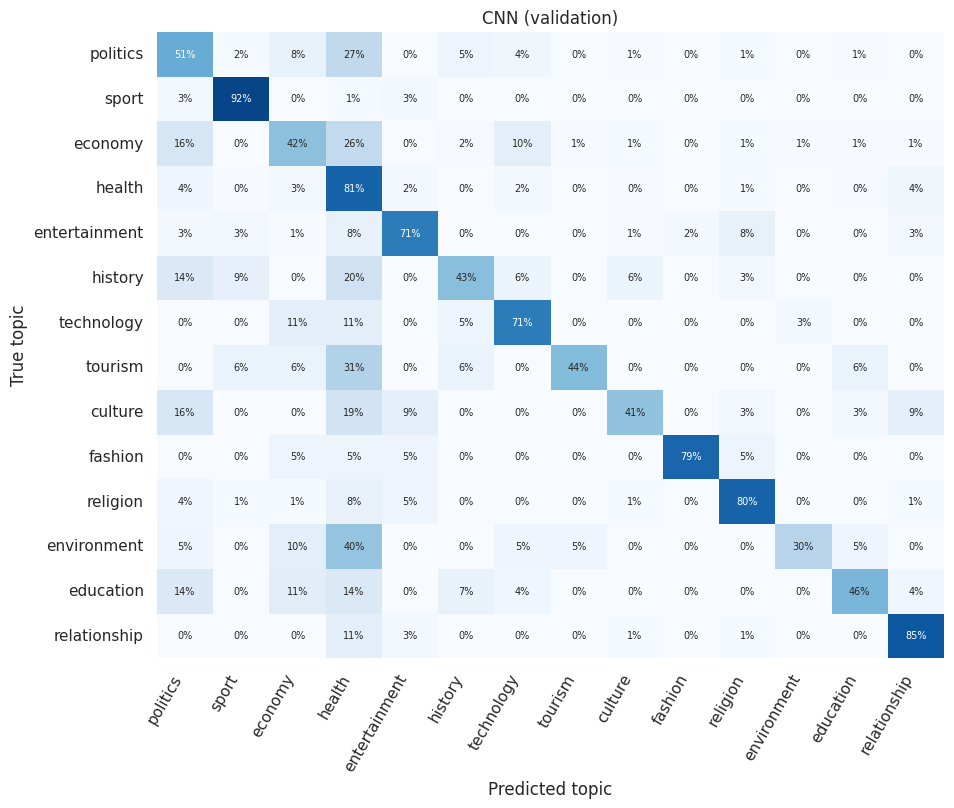

In [22]:
show_report("CNN (validation)", y_val, cnn_val_probs)

---
## Experiment 4: BiLSTM with attention

**Idea:** an LSTM reads the article word by word and remembers the context. **Bidirectional** means it reads forwards *and* backwards.
**Attention** lets the model learn *which words matter most* for the topic and focus on them, instead of treating all words the same.

Epoch  1 | Training loss: 2.5988 | Validation macro-F1: 0.1442
Epoch  2 | Training loss: 2.1967 | Validation macro-F1: 0.2732
Epoch  3 | Training loss: 1.8426 | Validation macro-F1: 0.3750
Epoch  4 | Training loss: 1.6518 | Validation macro-F1: 0.3879
Epoch  5 | Training loss: 1.4810 | Validation macro-F1: 0.3564
Epoch  6 | Training loss: 1.3405 | Validation macro-F1: 0.4153
Epoch  7 | Training loss: 1.2206 | Validation macro-F1: 0.4170
Epoch  8 | Training loss: 1.1265 | Validation macro-F1: 0.4823
Epoch  9 | Training loss: 1.0185 | Validation macro-F1: 0.4450
Epoch 10 | Training loss: 0.9268 | Validation macro-F1: 0.4341
Epoch 11 | Training loss: 0.8542 | Validation macro-F1: 0.4170
Epoch 12 | Training loss: 0.7837 | Validation macro-F1: 0.4297
Early stopping: validation macro-F1 did not improve.


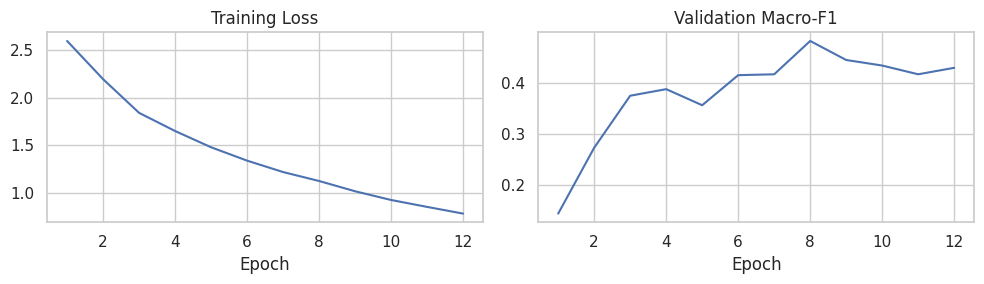

Validation scores: {'macro_f1': 0.4823, 'weighted_f1': 0.5815, 'accuracy': 0.5552, 'log_loss': 1.458}


In [23]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# ── 1. Define the BiLSTM with Attention ───────────────────────────────
class BiLSTMAttention(nn.Module):
    """Classify text using a bidirectional LSTM and attention."""

    def __init__(self, vocab_size, emb_dim, hidden, dropout, n_classes):
        super().__init__()

        # Convert word IDs into dense vectors.
        self.embedding = nn.Embedding(
            vocab_size, emb_dim, padding_idx=PAD
        )

        # Read the text in both forward and backward directions.
        self.lstm = nn.LSTM(
            input_size=emb_dim,
            hidden_size=hidden,
            batch_first=True,
            bidirectional=True
        )

        # Learn how important each word is for classification.
        self.attention = nn.Sequential(
            nn.Linear(2 * hidden, 2 * hidden),
            nn.Tanh(),
            nn.Linear(2 * hidden, 1, bias=False)
        )

        self.dropout = nn.Dropout(dropout)

        # Predict the article's topic from its final representation.
        self.classifier = nn.Linear(2 * hidden, n_classes)

    def forward(self, x):
        # Identify real words and ignore padding.
        is_word = x != PAD
        lengths = is_word.sum(dim=1).clamp(min=1)

        # Convert word IDs into embeddings.
        embedded = self.dropout(self.embedding(x))

        # Pack sequences so the LSTM does not process padding as text.
        packed = nn.utils.rnn.pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        # Process each article in both directions.
        packed_output, _ = self.lstm(packed)

        # Restore sequences to their original padded length.
        output, _ = nn.utils.rnn.pad_packed_sequence(
            packed_output,
            batch_first=True,
            total_length=x.size(1)
        )

        # Calculate an attention score for each word.
        scores = self.attention(output).squeeze(-1)

        # Prevent padding positions from receiving attention.
        scores = scores.masked_fill(~is_word, -1e9)

        # Convert scores into attention weights.
        weights = F.softmax(scores, dim=1)

        # Combine word representations using their attention weights.
        summary = (weights.unsqueeze(-1) * output).sum(dim=1)

        # Predict class scores (logits).
        return self.classifier(self.dropout(summary))


# ── 2. Configure the experiment ───────────────────────────────────────
settings = {
    "max_len": MAX_LEN,
    "emb_dim": 100,
    "hidden": 64,
    "dropout": 0.4,
    "class_weights": True,
    "lr": 1e-3,
    "batch_size": 64,
    "epochs": 15,
    "patience": 4
}


# ── 3. Train and evaluate the model ───────────────────────────────────
def run_experiment(name, notes):
    """Train the BiLSTM and evaluate it on the validation set."""

    network = BiLSTMAttention(
        vocab_size=len(vocab),
        emb_dim=settings["emb_dim"],
        hidden=settings["hidden"],
        dropout=settings["dropout"],
        n_classes=N_CLASSES
    )

    network = train_network(network, settings)

    # Generate probabilities for each topic.
    model = NeuralTextClassifier(network, settings["max_len"])
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    # Skip cross-validation because neural network training is expensive.
    cv_scores = None

    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


# ── 4. Run the experiment and save its results ────────────────────────
bilstm_model, bilstm_val_probs, bilstm_val_scores, bilstm_cv_scores = (
    run_experiment(
        "bilstm_attention_class_weights",
        "Bidirectional LSTM with attention and class weights."
    )
)

register_model(
    "bilstm_attention",
    "bilstm_attention_class_weights",
    bilstm_model,
    bilstm_val_scores,
    bilstm_cv_scores,
    settings
)

print("Validation scores:", {
    metric: round(score, 4)
    for metric, score in bilstm_val_scores.items()
})


               precision    recall  f1-score   support

     politics      0.700     0.314     0.434       312
        sport      0.898     0.922     0.910       258
      economy      0.523     0.409     0.459       193
       health      0.582     0.281     0.379       203
entertainment      0.830     0.680     0.748       266
      history      0.094     0.600     0.163        35
   technology      0.391     0.474     0.429        38
      tourism      0.164     0.562     0.254        16
      culture      0.192     0.438     0.267        32
      fashion      0.667     0.737     0.700        19
     religion      0.686     0.686     0.686       105
  environment      0.290     0.450     0.353        20
    education      0.144     0.500     0.224        28
 relationship      0.741     0.754     0.748       114

     accuracy                          0.555      1639
    macro avg      0.493     0.558     0.482      1639
 weighted avg      0.669     0.555     0.581      1639



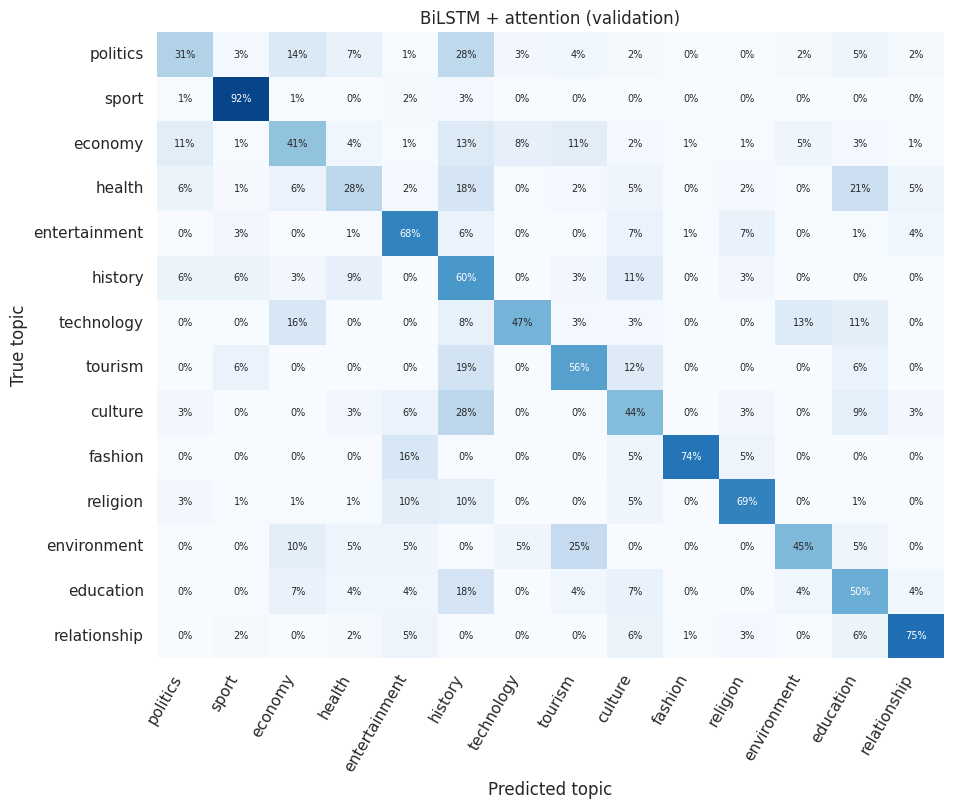

In [24]:
show_report("BiLSTM + attention (validation)", y_val, bilstm_val_probs)

---
## Experiment 5: BiLSTM with Word2Vec embeddings

**Idea:** so far the networks started with *random* word vectors. **Word2Vec** (skip-gram) first learns the vectors from our own training articles: words used in similar contexts get similar vectors. We then start the same BiLSTM + attention network from these vectors instead of random ones. (We train Word2Vec on the **training articles only**, so nothing leaks from validation or test.)

If this beats Experiment 4, good word embeddings help. If not, the network already learns enough by itself.

In [25]:
%pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 26.8 MB/s eta 0:00:00


Word2Vec vocabulary size: 71386
Matched 71,386 of 71,388 vocabulary words.
Epoch  1 | Training loss: 2.1099 | Validation macro-F1: 0.4420
Epoch  2 | Training loss: 1.3400 | Validation macro-F1: 0.5132
Epoch  3 | Training loss: 1.0788 | Validation macro-F1: 0.6038
Epoch  4 | Training loss: 0.9241 | Validation macro-F1: 0.6225
Epoch  5 | Training loss: 0.7911 | Validation macro-F1: 0.6234
Epoch  6 | Training loss: 0.6951 | Validation macro-F1: 0.6215
Epoch  7 | Training loss: 0.6034 | Validation macro-F1: 0.6320
Epoch  8 | Training loss: 0.5248 | Validation macro-F1: 0.6501
Epoch  9 | Training loss: 0.4588 | Validation macro-F1: 0.6514
Epoch 10 | Training loss: 0.4113 | Validation macro-F1: 0.6428
Epoch 11 | Training loss: 0.3470 | Validation macro-F1: 0.6676
Epoch 12 | Training loss: 0.3028 | Validation macro-F1: 0.6609
Epoch 13 | Training loss: 0.2519 | Validation macro-F1: 0.6493
Epoch 14 | Training loss: 0.2267 | Validation macro-F1: 0.6378
Epoch 15 | Training loss: 0.2007 | Validati

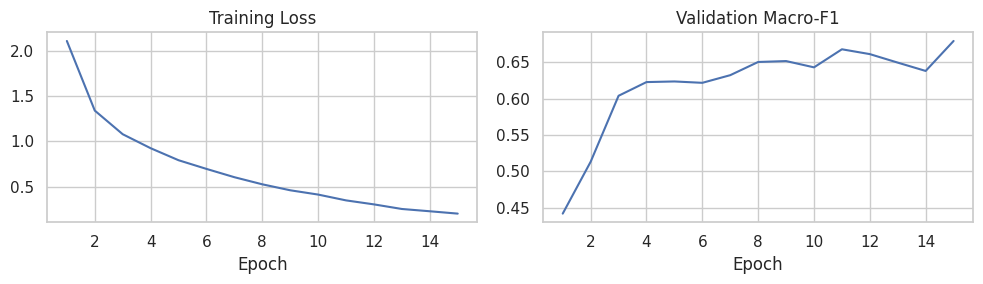

Validation scores: {'macro_f1': 0.679, 'weighted_f1': 0.7608, 'accuracy': 0.7566, 'log_loss': 1.0147}


In [26]:

# ── 1. Train Word2Vec using training articles only ────────────────────
from gensim.models import Word2Vec

# Convert each training article into a list of words.
sentences = [tokenize(text) for text in train_text]

w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,  # Number of values representing each word
    window=5,         # Consider nearby words within a window of 5
    min_count=2,      # Ignore words appearing fewer than twice
    sg=1,             # Use Skip-gram
    epochs=10,
    workers=1,
    seed=SEED
)

print("Word2Vec vocabulary size:", len(w2v.wv))


# ── 2. Create the embedding matrix ────────────────────────────────────
def make_word2vec_matrix(dim=100):
    """Create a matrix that matches our vocabulary's word IDs."""

    # Initialize words randomly when no Word2Vec vector is available.
    matrix = np.random.RandomState(SEED).normal(
        0, 0.1, size=(len(vocab), dim)
    ).astype("float32")

    # Padding must always have a zero vector.
    matrix[PAD] = 0.0

    found = 0

    # Replace random vectors with learned Word2Vec vectors where possible.
    for word, word_id in vocab.items():
        if word in w2v.wv:
            matrix[word_id] = w2v.wv[word]
            found += 1

    print(f"Matched {found:,} of {len(vocab):,} vocabulary words.")

    return torch.tensor(matrix, dtype=torch.float32)


# ── 3. Configure the BiLSTM experiment ────────────────────────────────
settings = {
    "max_len": MAX_LEN,
    "emb_dim": 100,
    "hidden": 64,
    "dropout": 0.4,
    "class_weights": True,
    "lr": 1e-3,
    "batch_size": 64,
    "epochs": 15,
    "patience": 4
}


# ── 4. Train and evaluate the model ───────────────────────────────────
def run_experiment(name, notes):
    """Train the BiLSTM with Word2Vec initialization."""

    network = BiLSTMAttention(
        vocab_size=len(vocab),
        emb_dim=settings["emb_dim"],
        hidden=settings["hidden"],
        dropout=settings["dropout"],
        n_classes=N_CLASSES
    )

    # Initialize the embedding layer with Word2Vec vectors.
    embedding_matrix = make_word2vec_matrix(settings["emb_dim"])

    with torch.no_grad():
        network.embedding.weight.copy_(embedding_matrix.to(device))

    # Train the model; embeddings remain trainable.
    network = train_network(network, settings)

    # Evaluate on validation data.
    model = NeuralTextClassifier(network, settings["max_len"])
    val_probs = model.predict_proba(val_text)
    val_scores = get_scores(y_val, val_probs)

    # Skip cross-validation to reduce training time.
    cv_scores = None

    log_experiment(name, notes, settings, val_scores, cv_scores)

    return model, val_probs, val_scores, cv_scores


#  Run the experiment and register the results ────────────────────
w2v_model, w2v_val_probs, w2v_val_scores, w2v_cv_scores = run_experiment(
    "bilstm_word2vec",
    "BiLSTM with attention initialized using Word2Vec Skip-gram embeddings."
)

register_model(
    "bilstm_word2vec",
    "bilstm_word2vec",
    w2v_model,
    w2v_val_scores,
    w2v_cv_scores,
    settings
)

print("Validation scores:", {
    metric: round(score, 4)
    for metric, score in w2v_val_scores.items()
})


               precision    recall  f1-score   support

     politics      0.697     0.670     0.683       312
        sport      0.957     0.953     0.955       258
      economy      0.713     0.658     0.685       193
       health      0.661     0.709     0.684       203
entertainment      0.880     0.823     0.850       266
      history      0.316     0.514     0.391        35
   technology      0.636     0.737     0.683        38
      tourism      0.750     0.562     0.643        16
      culture      0.452     0.438     0.444        32
      fashion      0.636     0.737     0.683        19
     religion      0.872     0.781     0.824       105
  environment      0.433     0.650     0.520        20
    education      0.514     0.679     0.585        28
 relationship      0.891     0.860     0.875       114

     accuracy                          0.757      1639
    macro avg      0.672     0.698     0.679      1639
 weighted avg      0.769     0.757     0.761      1639



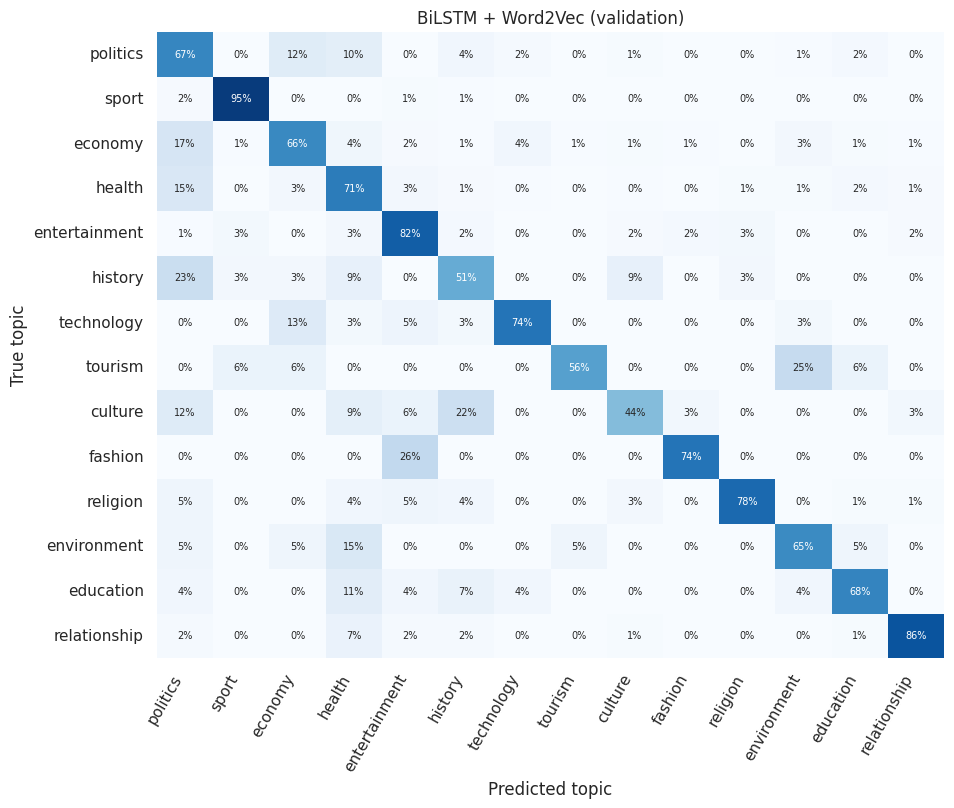

In [27]:
show_report("BiLSTM + Word2Vec (validation)", y_val, w2v_val_probs)

---
## Experiment 6: Transformer (AfroXLMR, fine-tuned)

**Idea:** a **Transformer** is a large network that was already pretrained on huge amounts of text. **AfroXLMR** was pretrained on 17 African languages, **including Kinyarwanda and Kirundi**. We only *fine-tune* it on our articles. This is usually the strongest approach for African languages because the model already "knows" the language.

It needs a **GPU** (for example a free Colab GPU). Without one, this cell is skipped automatically (the other experiments still run). Change `TRANSFORMER_CHECKPOINT` in the settings to try another model.

In [28]:

import sys
import traceback
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, TensorDataset
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, accuracy_score

# 1. Handle optional audio and vision packages.
# We only need text processing for this project.
for package in ["torchaudio", "torchvision"]:
    try:
        __import__(package)
    except Exception:
        sys.modules[package] = None

# Clear cached import checks if Transformers was already loaded.
if "transformers" in sys.modules:
    from transformers.utils import import_utils

    for item in vars(import_utils).values():
        if hasattr(item, "cache_clear"):
            item.cache_clear()

# 2. Load the Transformer libraries.
try:
    from transformers import (
        AutoTokenizer,
        AutoModelForSequenceClassification
    )

    # Check that XLM-RoBERTa model code can be imported.
    import transformers.models.xlm_roberta.modeling_xlm_roberta

except Exception as error:
    # Find the original error to make debugging easier.
    real_error = error

    while real_error.__cause__ or real_error.__context__:
        real_error = real_error.__cause__ or real_error.__context__

    error_frames = traceback.extract_tb(real_error.__traceback__)
    error_file = error_frames[-1].filename if error_frames else "Unknown"

    raise RuntimeError(
        f"Could not load Transformers.\n"
        f"Real error: {type(real_error).__name__}: {real_error}\n"
        f"Error file: {error_file}"
    ) from None

# 3. Set training parameters.
MAX_LENGTH = 128
BATCH_SIZE = 8
EPOCHS = 10
LEARNING_RATE = 2e-5

# Start with a small subset to reduce memory use.
# Change either value to None to use all available examples.
N_TRAIN = 800
N_VALIDATION = 300

# 4. Prepare training and validation data.
if N_TRAIN is None:
    training_texts = list(train_text)
    training_labels = np.asarray(y_train)
else:
    training_texts = list(train_text[:N_TRAIN])
    training_labels = np.asarray(y_train[:N_TRAIN])

if N_VALIDATION is None:
    validation_texts = list(val_text)
    validation_labels = np.asarray(y_val)
else:
    validation_texts = list(val_text[:N_VALIDATION])
    validation_labels = np.asarray(y_val[:N_VALIDATION])

# 5. Load the tokenizer and classification model.
tokenizer = AutoTokenizer.from_pretrained(TRANSFORMER_CHECKPOINT)

model = AutoModelForSequenceClassification.from_pretrained(
    TRANSFORMER_CHECKPOINT,
    num_labels=N_CLASSES
)

# Convert text into token IDs and attention masks.
encoded_texts = tokenizer(
    training_texts,
    truncation=True,
    max_length=MAX_LENGTH,
    padding="max_length",
    return_tensors="pt"
)

# Convert class labels into a PyTorch tensor.
labels_tensor = torch.tensor(
    training_labels,
    dtype=torch.long
)

# Combine tokenized text and labels into a dataset.
training_dataset = TensorDataset(
    encoded_texts["input_ids"],
    encoded_texts["attention_mask"],
    labels_tensor
)

# Create batches and shuffle the training examples.
training_loader = DataLoader(
    training_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# 6. Give more importance to less frequent classes.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(N_CLASSES),
    y=training_labels
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

# Measure prediction errors, accounting for class imbalance.
loss_function = nn.CrossEntropyLoss(weight=class_weights)

# AdamW updates the model's parameters during training.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=0.01
)

# 7. Create a function to predict class probabilities.
def predict_probabilities(texts):
    model.eval()
    all_probabilities = []

    # Disable gradient calculations during evaluation.
    with torch.no_grad():
        # Process 16 texts at a time to save memory.
        for start in range(0, len(texts), 16):
            batch_texts = texts[start:start + 16]

            batch_tokens = tokenizer(
                list(batch_texts),
                truncation=True,
                max_length=MAX_LENGTH,
                padding=True,
                return_tensors="pt"
            )

            # Get model scores and convert them into probabilities.
            outputs = model(**batch_tokens)
            probabilities = F.softmax(outputs.logits, dim=1)

            all_probabilities.append(probabilities.numpy())

    return np.vstack(all_probabilities)

# 8. Train the model and evaluate it after each epoch.
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_training_loss = 0.0

    # Display training progress.
    progress_bar = tqdm(
        training_loader,
        desc=f"Epoch {epoch}/{EPOCHS}"
    )

    for input_ids, attention_mask, labels in progress_bar:
        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Predict the classes for this batch.
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate the prediction error.
        loss = loss_function(outputs.logits, labels)

        # Calculate gradients and update the model.
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        # Add the batch loss to the running total.
        total_training_loss += loss.item() * len(labels)

        # Show the current batch loss.
        progress_bar.set_postfix(loss=f"{loss.item():.3f}")

    # Calculate average training loss.
    average_loss = total_training_loss / len(training_labels)

    # Predict labels for the validation data.
    validation_probabilities = predict_probabilities(validation_texts)
    validation_predictions = validation_probabilities.argmax(axis=1)

    # Evaluate the model using macro-F1 and accuracy.
    validation_macro_f1 = f1_score(
        validation_labels,
        validation_predictions,
        average="macro",
        labels=ALL_CLASSES,
        zero_division=0
    )

    validation_accuracy = accuracy_score(
        validation_labels,
        validation_predictions
    )

    # Print the results for this epoch.
    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"Training Loss: {average_loss:.4f} | "
        f"Validation Macro-F1: {validation_macro_f1:.4f} | "
        f"Validation Accuracy: {validation_accuracy:.4f}"
    )


config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

...

Epoch 8/10 | Training Loss: 0.2479 | Validation Macro-F1: 0.5657 | Validation Accuracy: 0.6800


Epoch 9/10:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 9/10 | Training Loss: 0.1761 | Validation Macro-F1: 0.5975 | Validation Accuracy: 0.6900


Epoch 10/10:   0%|          | 0/100 [00:00<?, ?it/s]

Epoch 10/10 | Training Loss: 0.1221 | Validation Macro-F1: 0.5824 | Validation Accuracy: 0.6800


               precision    recall  f1-score   support

     politics      0.615     0.615     0.615        52
        sport      0.864     0.974     0.916        39
      economy      0.531     0.548     0.540        31
       health      0.600     0.615     0.608        39
entertainment      0.737     0.840     0.785        50
      history      0.333     0.143     0.200         7
   technology      0.333     0.333     0.333         6
      tourism      0.667     0.400     0.500         5
      culture      1.000     0.857     0.923         7
      fashion      0.500     0.750     0.600         4
     religion      0.833     0.714     0.769        21
  environment      0.000     0.000     0.000         5
    education      0.833     0.500     0.625        10
 relationship      0.773     0.708     0.739        24

     accuracy                          0.680       300
    macro avg      0.616     0.571     0.582       300
 weighted avg      0.678     0.680     0.674       300



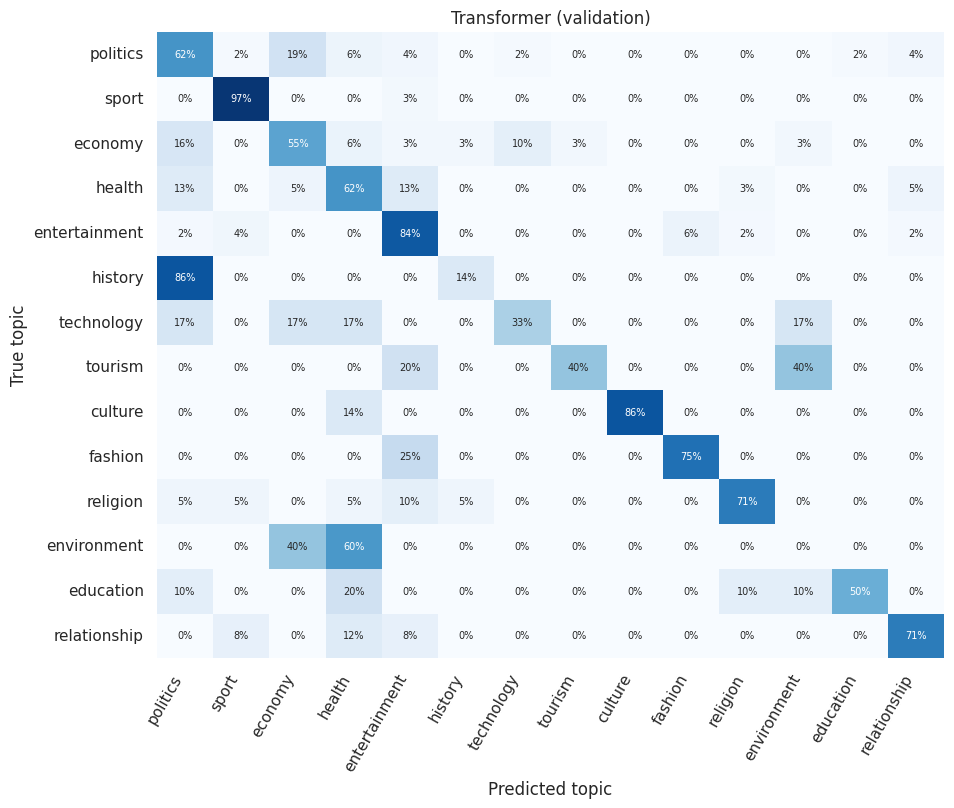

In [38]:
show_report(
    "Transformer (validation)",
    validation_labels,
    validation_probabilities
)

---
## Bonus experiment 7: Ensemble

**Idea:** different models make different mistakes. If we **average their probabilities**, many mistakes cancel out. No new training is needed.

In [29]:

# ── 1. Define the probability-averaging ensemble ──────────────────────
class AverageEnsemble:
    """Combine model predictions by averaging their class probabilities."""

    def __init__(self, models):
        self.models = models

    def predict_proba(self, texts):
        # Get probabilities from each model.
        predictions = [
            model.predict_proba(texts)
            for model in self.models
        ]

        # Average the probabilities for each class.
        return np.mean(predictions, axis=0)


# ── 2. Select models, excluding the simple baseline ───────────────────
members = [
    name for name in MODELS
    if name != "majority_baseline"
]

print("Ensemble members:", members)

ensemble_name = f"ensemble_of_{len(members)}"


# ── 3. Generate ensemble validation predictions ───────────────────────
ensemble_model = AverageEnsemble([
    MODELS[name] for name in members
])

ensemble_val_probs = ensemble_model.predict_proba(val_text)
ensemble_val_scores = get_scores(y_val, ensemble_val_probs)


# ── 4. Record and display results ─────────────────────────────────────
log_experiment(
    ensemble_name,
    "Average of the class probabilities from the selected models.",
    {},
    ensemble_val_scores,
    None
)

register_model(
    "ensemble",
    ensemble_name,
    ensemble_model,
    ensemble_val_scores,
    None,
    {"members": members}
)

print("Validation scores:", {
    metric: round(score, 4)
    for metric, score in ensemble_val_scores.items()
})


Ensemble members: ['logistic_regression', 'naive_bayes', 'cnn', 'bilstm_attention', 'bilstm_word2vec']
Validation scores: {'macro_f1': 0.6922, 'weighted_f1': 0.7751, 'accuracy': 0.7743, 'log_loss': 0.8743}


---
## 7. Compare all experiments on the validation set

We pick the best model with **validation macro-F1** (the test set is still untouched).

,experiment,notes,val_macro_f1,val_accuracy,val_log_loss,cv_macro_f1
0,word_bigrams_balanced,Word unigrams and bigrams with balanced class ...,0.7074,0.7877,1.1395,0.7252
1,ensemble_of_5,Average of the class probabilities from the se...,0.6922,0.7743,0.8743,NaN
2,bilstm_word2vec,BiLSTM with attention initialized using Word2V...,0.6790,0.7566,1.0147,NaN
3,complement_nb_bigrams,Complement Naive Bayes with TF-IDF unigrams an...,0.6240,0.7858,0.9895,0.6603
4,cnn_class_weights,"TextCNN with kernel sizes 3, 4, and 5, using c...",0.6086,0.6760,1.0026,NaN
5,bilstm_attention_class_weights,Bidirectional LSTM with attention and class we...,0.4823,0.5552,1.4580,NaN
6,majority_baseline,Simple baseline using the training class frequ...,0.0228,0.1904,2.2404,0.0229


,experiment,notes,val_macro_f1,val_accuracy,val_log_loss,cv_macro_f1
0,word_bigrams_balanced,Word unigrams and bigrams with balanced class ...,0.7074,0.7877,1.1395,0.7252
1,ensemble_of_5,Average of the class probabilities from the se...,0.6922,0.7743,0.8743,NaN
2,bilstm_word2vec,BiLSTM with attention initialized using Word2V...,0.6790,0.7566,1.0147,NaN
3,complement_nb_bigrams,Complement Naive Bayes with TF-IDF unigrams an...,0.6240,0.7858,0.9895,0.6603
4,cnn_class_weights,"TextCNN with kernel sizes 3, 4, and 5, using c...",0.6086,0.6760,1.0026,NaN
5,bilstm_attention_class_weights,Bidirectional LSTM with attention and class we...,0.4823,0.5552,1.4580,NaN
6,majority_baseline,Simple baseline using the training class frequ...,0.0228,0.1904,2.2404,0.0229


Best experiment on validation data: word_bigrams_balanced
Best experiment on validation data: word_bigrams_balanced


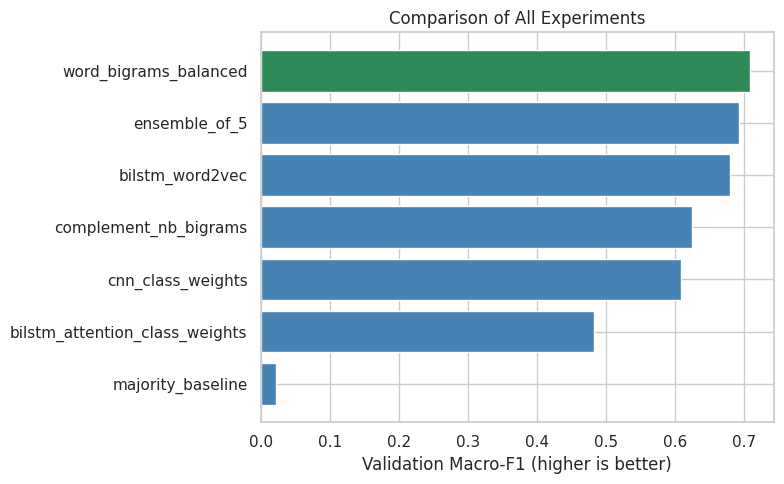

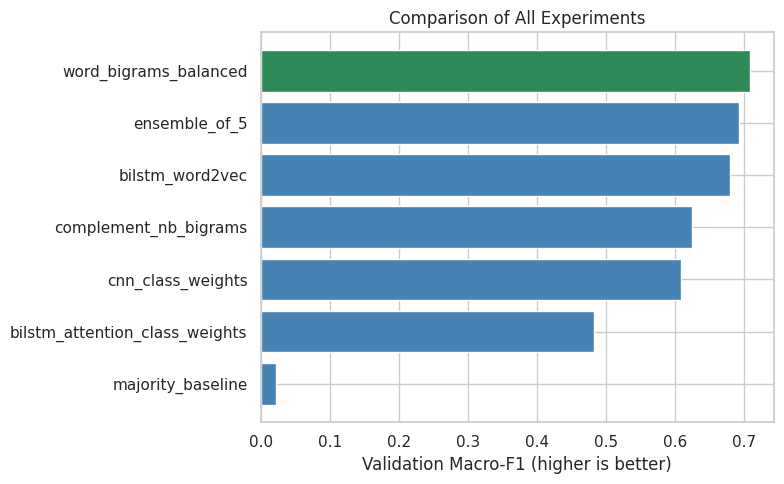

In [30]:

# ── 1. Create a table of experiment results ────────────────────────────
log_table = (
    pd.DataFrame(experiment_log)
    .sort_values("val_macro_f1", ascending=False)
    .reset_index(drop=True)
)

# Hide the detailed settings to make the table easier to read.
display(log_table.drop(columns=["settings"]).round(4))


# ── 2. Identify the best validation result ────────────────────────────
best_name = log_table.loc[0, "experiment"]

print(f"Best experiment on validation data: {best_name}")


# ── 3. Plot validation macro-F1 for all experiments ───────────────────
plt.figure(figsize=(8, 0.5 * len(log_table) + 1.5))

# Highlight the best experiment.
colors = [
    "seagreen" if name == best_name else "steelblue"
    for name in log_table["experiment"]
]

plt.barh(
    log_table["experiment"],
    log_table["val_macro_f1"],
    color=colors
)

# Place the highest-scoring experiment at the top.
plt.gca().invert_yaxis()

plt.xlabel("Validation Macro-F1 (higher is better)")
plt.title("Comparison of All Experiments")
plt.tight_layout()
plt.show()


---
## 8. Final test (used only once!)

Now, and only now, we score every model on the **test set**. We also look at each **topic** separately, because a model can be good on big topics (politics, sport) and weak on small ones (education, fashion).

,macro_f1,weighted_f1,accuracy,log_loss
logistic_regression,0.7125,0.7705,0.7694,1.1597
ensemble,0.6908,0.7647,0.7627,0.9005
bilstm_word2vec,0.6667,0.7534,0.7492,0.9909
naive_bayes,0.6479,0.7676,0.7779,1.0183
cnn,0.6131,0.6617,0.6589,1.0202
bilstm_attention,0.4637,0.5492,0.5265,1.5431
majority_baseline,0.0229,0.0612,0.1910,2.2433


Model selected using validation data: logistic_regression


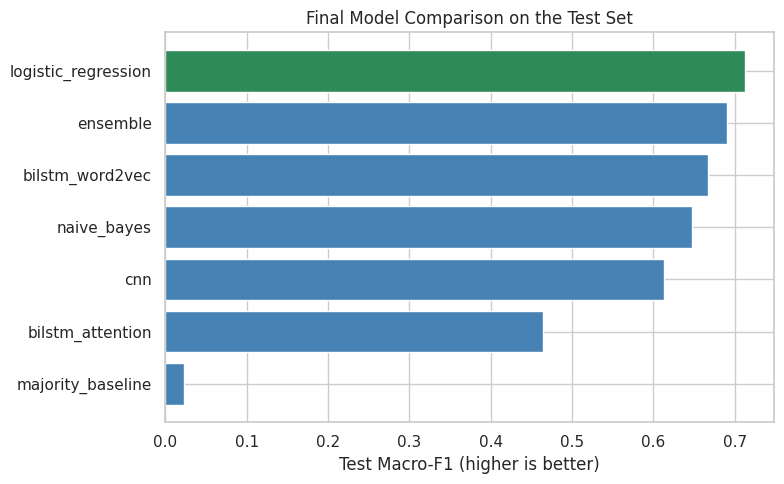

In [31]:

# ── 1. Prepare the final models ────────────────────────────────────────
final_models = dict(MODELS)

# Find the model selected using validation Macro-F1.
experiment_to_model = {
    info["experiment"]: key
    for key, info in RESULT_INFO.items()
}
best_model_name = experiment_to_model[best_name]

# ── 2. Evaluate every model on the test set ────────────────────────────
test_probs = {
    name: model.predict_proba(test_text)
    for name, model in final_models.items()
}

test_table = pd.DataFrame({
    name: get_scores(y_test, probabilities)
    for name, probabilities in test_probs.items()
}).T

# Display models from highest to lowest Macro-F1.
test_table = test_table.sort_values("macro_f1", ascending=False)
display(test_table.round(4))

print(f"Model selected using validation data: {best_model_name}")

# ── 3. Plot test Macro-F1 scores ───────────────────────────────────────
plt.figure(figsize=(8, 0.5 * len(test_table) + 1.5))

colors = [
    "seagreen" if name == best_model_name else "steelblue"
    for name in test_table.index
]

plt.barh(test_table.index, test_table["macro_f1"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("Test Macro-F1 (higher is better)")
plt.title("Final Model Comparison on the Test Set")
plt.tight_layout()
plt.show()


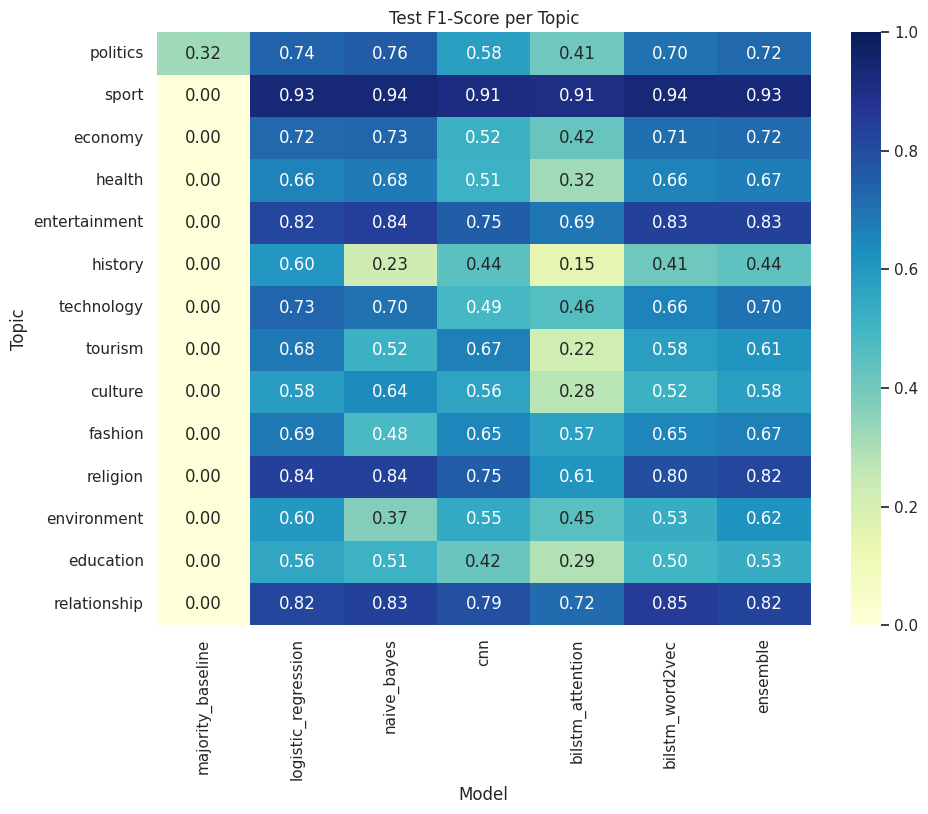

,test articles,majority_baseline,logistic_regression,naive_bayes,cnn,bilstm_attention,bilstm_word2vec,ensemble
politics,313,0.321,0.738,0.757,0.576,0.409,0.700,0.725
sport,257,0.000,0.935,0.936,0.911,0.909,0.936,0.933
economy,192,0.000,0.724,0.734,0.521,0.424,0.707,0.722
health,204,0.000,0.660,0.682,0.514,0.320,0.662,0.668
entertainment,265,0.000,0.820,0.842,0.747,0.689,0.834,0.834
history,34,0.000,0.603,0.227,0.442,0.149,0.408,0.440
technology,38,0.000,0.729,0.700,0.491,0.458,0.658,0.699
tourism,17,0.000,0.684,0.516,0.667,0.219,0.579,0.611
culture,32,0.000,0.585,0.640,0.562,0.277,0.516,0.576
fashion,20,0.000,0.686,0.483,0.650,0.571,0.651,0.667


In [32]:

# ── 1. Calculate F1-score for each topic and model ─────────────────────
per_class = pd.DataFrame(
    {
        name: f1_score(
            y_test,
            probabilities.argmax(axis=1),
            average=None,
            labels=ALL_CLASSES,
            zero_division=0
        )
        for name, probabilities in test_probs.items()
    },
    index=LABELS
)

# Add the number of test articles in each topic.
per_class.insert(
    0,
    "test articles",
    np.bincount(y_test, minlength=N_CLASSES)
)

# ── 2. Plot the per-topic F1-scores ────────────────────────────────────
plt.figure(figsize=(1.0 * len(test_probs) + 3, 0.45 * N_CLASSES + 2))

sns.heatmap(
    per_class.drop(columns="test articles"),
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1
)

plt.title("Test F1-Score per Topic")
plt.ylabel("Topic")
plt.xlabel("Model")
plt.tight_layout()
plt.show()

# ── 3. Display the results as a table ──────────────────────────────────
display(per_class.round(3))


               precision    recall  f1-score   support

     politics      0.784     0.696     0.738       313
        sport      0.952     0.918     0.935       257
      economy      0.704     0.745     0.724       192
       health      0.645     0.676     0.660       204
entertainment      0.824     0.815     0.820       265
      history      0.564     0.647     0.603        34
   technology      0.660     0.816     0.729        38
      tourism      0.619     0.765     0.684        17
      culture      0.576     0.594     0.585        32
      fashion      0.800     0.600     0.686        20
     religion      0.838     0.838     0.838       105
  environment      0.632     0.571     0.600        21
    education      0.515     0.607     0.557        28
 relationship      0.787     0.850     0.817       113

     accuracy                          0.769      1639
    macro avg      0.707     0.724     0.713      1639
 weighted avg      0.774     0.769     0.771      1639



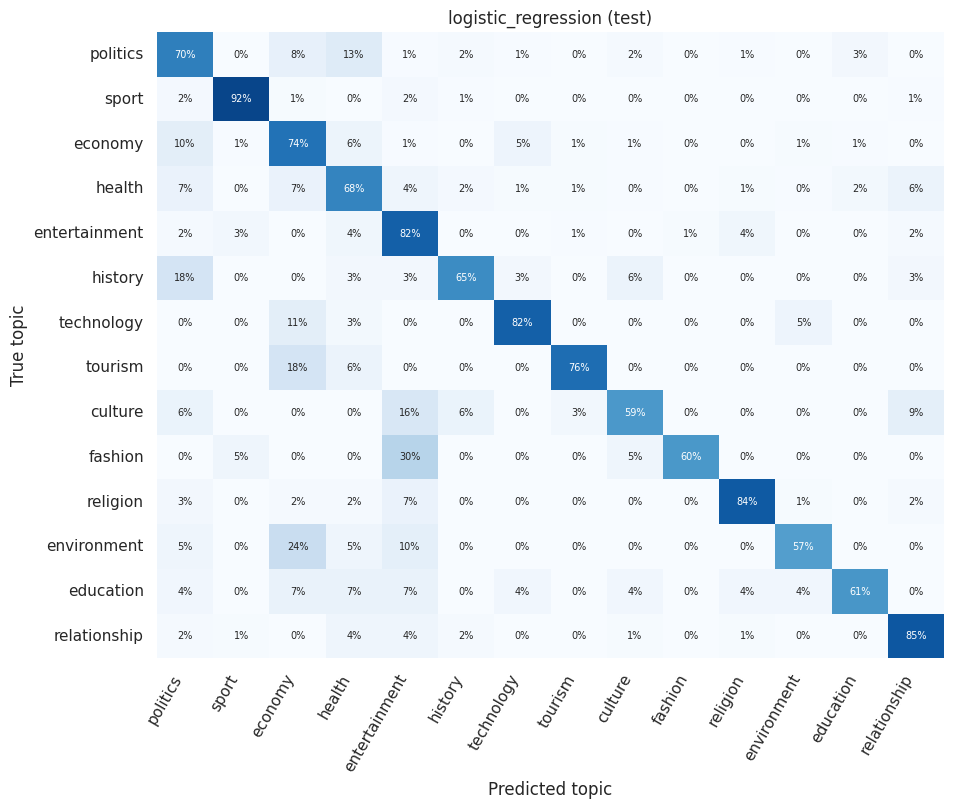

In [33]:
# Detailed look at the model we chose on validation
show_report(f"{best_model_name} (test)", y_test, test_probs[best_model_name])

---
## 9. Error analysis

A score alone does not tell us **why** a model fails. Here we study the articles that the chosen model classified **wrongly on the test set**:

1. Which topics get mixed up?
2. Which topics are hardest, and does that follow how many training articles they have?
3. Do long articles fail more often?
4. Was the model confident when it was wrong?
5. What do the wrongly classified articles look like? (printed only if `SHOW_ERROR_EXAMPLES = True`)

All wrongly classified articles are also saved to a CSV file so you can read them and describe the reasons in your report.

Selected model: logistic_regression
Misclassified: 378 of 1639 articles (23.1%)

1. Most frequent confusions (true topic → predicted topic)


,true,predicted,mistakes
0,politics,health,40
1,politics,economy,26
2,economy,politics,20
3,health,economy,14
4,health,politics,14
5,health,relationship,12
6,entertainment,religion,11
7,economy,health,11
8,entertainment,health,11
9,economy,technology,10


2. Error rate per topic and training-set size


,error rate,mistakes,test articles,training articles
true,,,,
environment,0.429,9,21,97
culture,0.406,13,32,151
fashion,0.400,8,20,90
education,0.393,11,28,130
history,0.353,12,34,160
health,0.324,66,204,948
politics,0.304,95,313,1457
economy,0.255,49,192,898
tourism,0.235,4,17,76


3. Error rate by article length


,error rate,articles
length group,,
1–50 words,0.222,27
51–100,0.187,75
101–200,0.254,564
201–400,0.231,752
401+,0.186,221


4. Model confidence
Average confidence when correct: 0.46
Average confidence when wrong:   0.28
Wrong predictions with confidence > 0.80: 5 of 378 mistakes


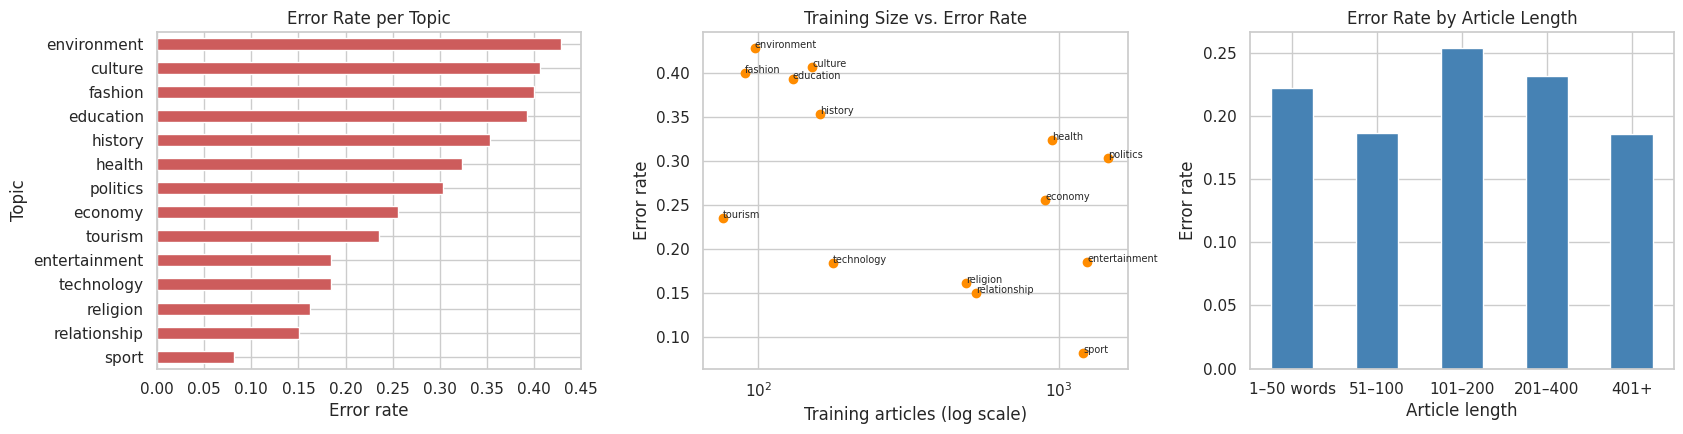


Saved 378 misclassified articles to: /content/results/kinnews/misclassified_test.csv


In [34]:

# ── 1. Collect predictions and identify mistakes ──────────────────────
best_probs = test_probs[best_model_name]

errors = test.copy()
errors["true"] = [LABELS[i] for i in y_test]
errors["predicted"] = [LABELS[i] for i in best_probs.argmax(axis=1)]
errors["confidence"] = best_probs.max(axis=1).round(3)
errors["n_words"] = errors["text"].str.split().str.len()
errors["wrong"] = errors["true"] != errors["predicted"]

wrong = errors[errors["wrong"]]

print(f"Selected model: {best_model_name}")
print(
    f"Misclassified: {len(wrong)} of {len(errors)} articles "
    f"({errors['wrong'].mean():.1%})\n"
)

# ── 2. Find the most frequent topic confusions ─────────────────────────
print("1. Most frequent confusions (true topic → predicted topic)")

top_confusions = (
    wrong.groupby(["true", "predicted"])
    .size()
    .sort_values(ascending=False)
    .head(10)
    .rename("mistakes")
    .reset_index()
)

display(top_confusions)

# ── 3. Calculate the error rate for each topic ─────────────────────────
by_topic = (
    errors.groupby("true")["wrong"]
    .agg(["mean", "sum", "count"])
    .rename(columns={
        "mean": "error rate",
        "sum": "mistakes",
        "count": "test articles"
    })
)

# Add the number of training articles for each topic.
training_counts = train["category"].value_counts()
by_topic["training articles"] = training_counts.reindex(by_topic.index)

by_topic = by_topic.reindex(LABELS).sort_values(
    "error rate", ascending=False
)

print("2. Error rate per topic and training-set size")
display(by_topic.round(3))

# ── 4. Check whether article length affects errors ────────────────────
errors["length group"] = pd.cut(
    errors["n_words"],
    bins=[0, 50, 100, 200, 400, float("inf")],
    labels=["1–50 words", "51–100", "101–200", "201–400", "401+"]
)

by_length = (
    errors.groupby("length group", observed=True)["wrong"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "error rate",
        "count": "articles"
    })
)

print("3. Error rate by article length")
display(by_length.round(3))

# ── 5. Examine prediction confidence ──────────────────────────────────
correct = errors[~errors["wrong"]]

print("4. Model confidence")
print(f"Average confidence when correct: {correct['confidence'].mean():.2f}")
print(f"Average confidence when wrong:   {wrong['confidence'].mean():.2f}")
print(
    "Wrong predictions with confidence > 0.80: "
    f"{(wrong['confidence'] > 0.80).sum()} of {len(wrong)} mistakes"
)

# ── 6. Visualize the error analysis ────────────────────────────────────
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# Error rate by topic.
by_topic["error rate"].sort_values().plot.barh(
    ax=ax[0], color="indianred"
)
ax[0].set_title("Error Rate per Topic")
ax[0].set_xlabel("Error rate")
ax[0].set_ylabel("Topic")

# Compare training-set size with error rate.
ax[1].scatter(
    by_topic["training articles"],
    by_topic["error rate"],
    color="darkorange"
)

for topic, row in by_topic.iterrows():
    if pd.notna(row["training articles"]):
        ax[1].annotate(
            topic,
            (row["training articles"], row["error rate"]),
            fontsize=7
        )

ax[1].set_xscale("log")
ax[1].set_xlabel("Training articles (log scale)")
ax[1].set_ylabel("Error rate")
ax[1].set_title("Training Size vs. Error Rate")

# Error rate by article length.
by_length["error rate"].plot.bar(
    ax=ax[2], color="steelblue", rot=0
)
ax[2].set_title("Error Rate by Article Length")
ax[2].set_xlabel("Article length")
ax[2].set_ylabel("Error rate")

plt.tight_layout()
plt.show()

# ── 7. Save mistakes for manual review and the report ──────────────────
RESULTS_DIR = ROOT / "results" / DATASET
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

error_file = RESULTS_DIR / "misclassified_test.csv"

wrong[
    ["true", "predicted", "confidence", "n_words", "text"]
].to_csv(error_file, index=False)

print(f"\nSaved {len(wrong)} misclassified articles to: {error_file}")


In [35]:

# ── 5. Inspect examples of misclassified articles ──────────────────────
if SHOW_ERROR_EXAMPLES:

    # Group mistakes by their true and predicted topics.
    for (true_topic, predicted_topic), group in wrong.groupby(
        ["true", "predicted"]
    ):
        # Skip confusion pairs with fewer than 3 mistakes.
        if len(group) < 3:
            continue

        print(
            f"\n--- True: {true_topic} → Predicted: {predicted_topic} "
            f"({len(group)} articles)"
        )

        # Show the most confident wrong predictions first.
        examples = group.sort_values(
            "confidence", ascending=False
        ).head(N_ERROR_EXAMPLES)

        for _, row in examples.iterrows():
            print(f"Confidence: {row['confidence']:.2f}")
            print(f"Text: {row['text'][:200]}...")
else:
    print(
        "Examples are hidden (SHOW_ERROR_EXAMPLES = False). "
        "Open the misclassified_test.csv file in the results folder."
    )



--- True: culture → Predicted: entertainment (5 articles)
Confidence: 0.33
Text: abategura miss rwanda basabye imbabazi nyuma y’uko abahatanira ikamba bakamiye tudobo. nyuma y’uko hacicikanye amafoto y’abahatanira ikamba miss rwanda bakamira tudobo tuvamo isabune omo nomi abategur...
Confidence: 0.32
Text: abataramyi b’i rwanda’ bateguye igitaramo cy’umuco bise ngwino ku gicumbi iwacu. itsinda ry’abasore n’inkumi rizwi nk’ abataramyi b’i rwanda risanzwe ritegura ibikorwa byinshi gushyigikira gusigasira ...
Confidence: 0.28
Text: miss rwanda amajonjora yatangiriye karere musanzeamafoto. amajonjora gutora nyampinga w’u rwanda w’umwaka yamaze gutangira yahereye ntara y’amajyaruguru akaba yakorewe karere musanze muri aka karere h...

--- True: culture → Predicted: relationship (3 articles)
Confidence: 0.66
Text: impamvu mukobwa ukwiriye kwifotoza amafoto y’ubwambure bwe. umuvuduko w’iterambere ry’isi kugenderaho ujyana nuw’ ikoranabuhanga rusange muri gihe telefoni zigezweho zifasha abant

### How to explain the errors in your report

Use the tables above and the examples to discuss **possible reasons**. Typical reasons for news topic classifiers:

* **Overlapping topics.** A news story about a minister opening a hospital is *politics*, *health* and *economy* at once. Check the confusion table: are most mistakes between related topics?
* **Rare topics.** Topics with few training articles (look at the "training articles" column) give the model little to learn from. Compare the error rate with the number of training articles.
* **Long articles.** The neural networks only read the first `MAX_LEN` words. If long articles fail more, the missing text may be the reason.
* **Noisy labels.** We found articles whose identical text carried **two different topic labels** in the original data, so some "mistakes" may be questionable labels.
* **Source style.** Articles come from different websites and newspapers with different writing styles.
* **Vocabulary.** Kinyarwanda and Kirundi words have many prefixes and endings, so a word form never seen in training becomes `<unk>`. Models with sub-word input (the Transformer) handle this better.
* **Cleaning and duplicates.** We removed duplicates so scores are honest, but this also reduced the data, especially for the small topics.

Tie each reason to **evidence** (a number from the tables or an example). That is what makes an error analysis convincing.

---
## 10. Deploy: save the model into the `models/` folder

The web app must give **exactly the same predictions** as this notebook. So the next cells:

1. save the chosen model into **`models/<dataset>/`** (if the best model is the **ensemble**, all its members are saved),
2. write `api/nlp_utils.py` from **the same functions and classes used in this notebook** (cleaning, tokenizer, networks), so the web app cannot drift away from the notebook,
3. write `api/requirements.txt` with the library versions used here,
4. **test** that the API's model gives the same probabilities as the notebook on 100 test articles.

Run this notebook once with `DATASET = "kinnews"` and once with `DATASET = "kirnews"`: the web page then lets the user choose between **both languages**.

After it runs, start the **FastAPI** server from the project folder. It loads the models from `models/` and also serves the HTML page:

```
pip install -r api/requirements.txt
uvicorn main:app --app-dir api --port 8000
```
then open <http://localhost:8000> in your browser.

In [40]:

# ── Save only the best model selected using validation data ────────────
import joblib
import shutil

# Create the folder for this dataset if it does not exist.
MODEL_DIR = ROOT / "models" / DATASET
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Get the best-performing model and create its own folder.
model = MODELS[best_model_name]
folder = MODEL_DIR / best_model_name

# Remove an old copy of this model before saving the updated version.
if folder.exists():
    shutil.rmtree(folder)
folder.mkdir(parents=True)

# Save the model according to its type.
if isinstance(model, NeuralTextClassifier):
    # Save neural network weights.
    torch.save(model.network.state_dict(), folder / "weights.pt")

    # Save the vocabulary needed to convert text into token IDs.
    (MODEL_DIR / "vocab.json").write_text(
        json.dumps(vocab, ensure_ascii=False),
        encoding="utf-8"
    )

elif type(model).__name__ == "TransformerTextClassifier":
    # Save the transformer model and tokenizer.
    model.network.save_pretrained(folder)
    model.tokenizer.save_pretrained(folder)

else:
    # Save a scikit-learn pipeline, such as TF-IDF + Logistic Regression.
    joblib.dump(model, folder / "model.joblib")

# Confirm where the model was saved.
print(f"Saved best model ({best_model_name}) to: {folder}")


Saved best model (logistic_regression) to: /content/models/kinnews/logistic_regression


---
## 11. All results in one place

This cell prints everything (data, every experiment, test scores, per-topic reports) and saves the same text to `results/<dataset>/all_results.txt`, ready to copy into your report.

In [41]:
# ── Calculate dataset statistics for the report ──

n_start = len(df)

# Update these values using the actual counts from your preprocessing.
# Do not assume they are zero if you removed any records.
n_empty = 0
n_conflict = 0
n_dup_removed = 0

In [42]:

# ── 1. Prepare a report and helper functions ───────────────────────────
report_lines = []

def say(text=""):
    """Print a line and save it for the report."""
    print(text)
    report_lines.append(str(text))


def section(title):
    """Print a section heading."""
    say("\n" + "=" * 72)
    say(title)
    say("=" * 72)


# ── 2. Dataset summary ─────────────────────────────────────────────────
section(f"1. DATA ({info['language']}, dataset = {DATASET})")

say(f"Split mode: {SPLIT_MODE} | Topics ({N_CLASSES}): {LABELS}")
say(
    f"Original articles: {n_start:,} | Empty removed: {n_empty:,} | "
    f"Conflicting labels: {n_conflict:,} | Duplicates removed: {n_dup_removed:,} | "
    f"Remaining: {n_start - n_empty - n_conflict - n_dup_removed:,}"
)
say(
    f"Topics removed for having fewer than {MIN_ARTICLES_PER_CLASS} articles: "
    f"{too_small.to_dict() if len(too_small) else 'none'}"
)
say(split_summary.to_string())


# ── 3. Experiment settings and validation results ──────────────────────
section("2. ALL EXPERIMENTS (best validation Macro-F1 first)")
say(log_table.drop(columns=["settings"]).round(4).to_string())

for row in experiment_log:
    say(f"\n- {row['experiment']}: {row['notes']}")
    say(f"  Settings: {row['settings']}")

section("3. VALIDATION AND CROSS-VALIDATION SCORES")

for key, model_info in RESULT_INFO.items():
    val = model_info["val_scores"]
    cv = model_info["cv_scores"]

    say(
        f"{key:20s} Validation: Macro-F1 {val['macro_f1']:.4f} | "
        f"Weighted-F1 {val['weighted_f1']:.4f} | "
        f"Accuracy {val['accuracy']:.4f} | Log loss {val['log_loss']:.4f}"
    )

    cv_result = (
        f"{cv['macro_f1_mean']:.4f} ± {cv['macro_f1_std']:.4f}"
        if cv else "not run"
    )
    say(f"{'':20s} 5-fold CV Macro-F1: {cv_result}")


# ── 4. Final test results ───────────────────────────────────────────────
section("4. TEST SCORES")
say(test_table.sort_values("macro_f1", ascending=False).round(4).to_string())
say(f"\nModel selected using validation data: {best_model_name}")


# ── 5. Classification report for every model ───────────────────────────
section("5. PER-TOPIC CLASSIFICATION REPORTS")

for name, probabilities in test_probs.items():
    say(f"\n--- {name}")

    say(classification_report(
        y_test,
        probabilities.argmax(axis=1),
        labels=ALL_CLASSES,
        target_names=LABELS,
        zero_division=0,
        digits=3
    ))


# ── 6. F1-score for each topic ──────────────────────────────────────────
section("6. TEST F1-SCORE PER TOPIC")
say(per_class.round(3).to_string())


# ── 7. Save the report and result tables ───────────────────────────────
RESULTS_DIR = ROOT / "results" / DATASET
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete text report and separate CSV tables.
(RESULTS_DIR / "all_results.txt").write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

log_table.to_csv(RESULTS_DIR / "experiment_log.csv", index=False)
test_table.to_csv(RESULTS_DIR / "test_scores.csv")
per_class.to_csv(RESULTS_DIR / "test_f1_per_topic.csv")

print(f"\nAll reports and CSV files saved to: {RESULTS_DIR}")



1. DATA (Kinyarwanda, dataset = kinnews)
Split mode: general | Topics (14): ['politics', 'sport', 'economy', 'health', 'entertainment', 'history', 'technology', 'tourism', 'culture', 'fashion', 'religion', 'environment', 'education', 'relationship']
Original articles: 10,924 | Empty removed: 0 | Conflicting labels: 0 | Duplicates removed: 0 | Remaining: 10,924
Topics removed for having fewer than 20 articles: none
               train  validation  test  total
category                                     
politics        1457         312   313   2082
sport           1203         258   257   1718
economy          898         193   192   1283
health           948         203   204   1355
entertainment   1238         266   265   1769
history          160          35    34    229
technology       177          38    38    253
tourism           76          16    17    109
culture          151          32    32    215
fashion           90          19    20    129
religion         491         

---
## How to read the results

* **Use macro-F1, not accuracy.** Politics, sport and economy are big topics. A model can have high accuracy and still fail on the small topics.
* **Compare every model with the baseline.** If a model is not clearly better than Experiment 0, it has learned nothing useful.
* **Look at each topic.** One overall number can hide weak topics (see the per-topic table).
* **Small test topics are noisy.** A topic with only a few test articles can swing several points. Say this in the report.
* **To improve a model:** change the numbers in its `settings` dictionary, re-run that one experiment and compare the validation macro-F1 in Section 7.